<center><h1>Hands-On Reinforcement Learning Applied to Trade Execution Algorithms</h1></center>
<center>
Autor: <cite><a href="https://www.linkedin.com/in/aoteog/">Oteo García, Alberto</a></cite>
</center>
<center>
Autor: <cite><a href="https://www.linkedin.com/in/jesus-sanz/">Sanz del Real, Jesús</a></cite>
</center>

----------------


**Taller 3 · Aprendizaje por Refuerzo · MIAX** — Óscar Romero Quincoces · Fernando Dapena Tauste · Daniel García López

Este es el notebook del taller completado, con los cuatro ejercicios. **El texto del profesor se mantiene intacto** y lo nuestro va en celdas aparte. Cada bloque que cambia respecto al LAB lleva la marca `🔧 Bloque modificado · Ej. N`.

| Ej. | Puntos | Dónde está | Qué se resuelve |
|---|---:|---|---|
| 1 | 3,5 | Celdas del propio LAB: entorno, TWAP, parámetros, buffer, entrenamiento y gráficos | Entrenamiento y ejecución completos de un Double DQN |
| 2 | 3,5 | Sección **Ejercicio 2** | Recompensa que hace que el agente copie al TWAP y ajuste motivado de la parametría |
| 3 | 1,5 | Sección **Ejercicio 3** | ε que baja según la mejora del agente, no según el número de episodios |
| 4 | 1,5 | Sección **Ejercicio 4** | Ideas A, B y C del enunciado y dos extras (pasillo y robustez) |

El código está en [`common/`](common) y el detalle de cada decisión, con su prueba, en [`docs/DECISIONES.md`](../docs/DECISIONES.md) y en los notebooks de cada ejercicio (`ej1_…` a `ej4_…`). El Ej. 1 entrena en directo (≈2 min) y el resto carga los resultados de `results/`.

<center><h1>Resumen</h1></center>

<center>

<p style="width:80%">
    En este notebook se presenta el taller de aprendizaje por refuerzo aplicado a un caso real para finanzas. 
    El objetivo es plantear, desde cero, la resolución del problema de <b>algoritmos de ejecución</b> a través del uso
    de técnicas de aprendizaje por refuerzo. Para ello, durante el taller se ha de completar el entorno básico <b>BestExecutionEnv</b> donde los asistentes desarrollarán las partes claves del
    código para obtener un simulador de mercado que, aunque relativamente naive, será funcional. Posteriormente, los participantes tendrán que aplicar algoritmos clásicos y basados en inteligencia artificial (IA) para la
    resolución del problema. 
</p>
<p style="width:80%">
    En términos sencillos, el problema de <b>algoritmos de ejecución</b> trata sobre la ejecución de órdenes con un tamaño lo suficientemente grande como para que su ejecución suponga un <b><i>'problema'</i></b>, como se ha comentado durante la explicación del caso práctico. La resolución de la ejecución de estas órdenes (órdenes CARE) se puede realizar utilizando diferentes aproximaciones. En el caso de este taller, queremos optimizar el <b><i>timing</i></b> de nuestras órdenes para minimizar el impacto de mercado. Es decir, buscaremos trocear la orden CARE para comprar (vender) a los menores (mayores) precios de la sesión en la que se ejecuta la orden CARE. Como baseline para saber si nuestra ejecución es buena, o mala, utilizaremos el baseline habitual en el sector: el VWAP slippage.
</p> 
<p style="width:80%">
El VWAP slippage es la desviación, en puntos básicos, del VWAP del mercado en comparación con el VWAP de nuestro algoritmo. Siendo el VWAP el precio medio ponderado por el volumen:
</p>   
    
$$\frac{\sum_{i=1}^T p_i\cdot v_i}{\sum_{i=1}^Tv_i}$$

</center>

---

<center><h1>Datos</h1></center>

<center>
<p style="width:80%">
Los datos para este taller se han extraído de los activos Repsol y Santander (<i>rep_data.pkl</i> y <i>san_data.pkl</i>). Entre la información extraída contamos con la primera posición del libro de órdenes, tanto del bid como del ask, así como el volumen acumulado, todo ello realizando una agrupación por 5 segundos. Las sesiones extraidas del libro de órdenes están comprendidas entre las 13:00h y las 17:25h. El conjunto de datos está partido en 3 subconjuntos, para los siguientes días bursátiles:
</p>
    
</center> 
<center>
    <p style="width:35%"><b>Train</b>: Primeros 60 días hábiles de 2018</p>
    <p style="width:35%"><b>Validación</b>: Primeros 30 días hábiles de 2019</p>
    <p style="width:35%"><b>Test</b>: Intervalo de los días hábiles del 31 al 60 de 2019 (30 días)</p>
</center>

<center>
<p style="width:80%">
<b>Adicionalmente</b>, para aquellos que quieran aumentar el grado de detalle, se han añadido otros dos ficheros con información más completa del libro de órdenes y de las ejecuciones de mercado. El fichero <i>orderbook.pkl</i> contiene las posiciones (precios y volúmenes) de hasta la tercera posición del libro de órdenes, agrupados por 5 segundos; el fichero <i>executions.pkl</i> todas las ejecuciones del mercado. En ambos casos, se trata de información para la compañía Repsol, entre las 13:00h y 17:25h de la sesión. El conjunto de datos está partido en 3 subconjuntos, para los siguientes días bursátiles:
</p>
    
</center> 
<center>
    <p style="width:35%"><b>Train</b>: Primeros 40 días hábiles de 2019</p>
    <p style="width:35%"><b>Validación</b>: Intervalo del 41 al 60 de 2019 (20 días)</p>
    <p style="width:35%"><b>Test</b>: Intervalo del 61 al 80 de 2019 (20 días)</p>
</center>

# Ejercicio 1 · Completar el LAB y entrenar de principio a fin

| | |
|---|---|
| **Qué pide** | Un entorno de RL completo, el orden correcto de interacción entre componentes, y un entrenamiento y una ejecución completos |
| **Qué hacemos** | Rellenamos cada hueco del LAB en su sitio, con el código en `common/` (PyTorch y Double DQN) y **la recompensa del taller sin cambios** |
| **Resultado** | Completa todas las órdenes, pero acaba mucho antes que el TWAP: la recompensa del LAB no reparte en el tiempo. Las cifras exactas están en las tarjetas del final, calculadas en esta ejecución |

> 🔧 **Bloque modificado · Ej. 1** — imports desde `common/` en lugar de `src/`: PyTorch en vez de TensorFlow, que el enunciado permite. Solo se usan los datos de Repsol (`rep_data.pkl`).

In [1]:
import sys
from pathlib import Path
NB = Path.cwd() if (Path.cwd() / "common").is_dir() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NB))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import display, Markdown
from common import data as dt, rewards as rw, exploration as ex, protocol as pr, plots as pl, ej3, ej4, lab
from common.env import BestExecutionEnv
from common.agents import DDQNAgent, TWAPAgent
from common.lab import kpis, codigo
torch.set_num_threads(1); lab.setup()
%matplotlib inline
DATA = dt.load("REP"); train = DATA["train"]
GRID = pr.make_grid(train, n_days=3, seed=0)   # 27 órdenes fijas: 3 días × 3 duraciones × 3 tamaños

> 🔧 **Bloque modificado · Ej. 1** — datos: **Repsol (REP)**. Se aprende solo con `train`; `val` sirve para elegir el modelo y `test` se mira una única vez al final.

,días,bins de 5 s por día
train,60,3177-3181
val,30,3179-3181
test,30,3179-3181


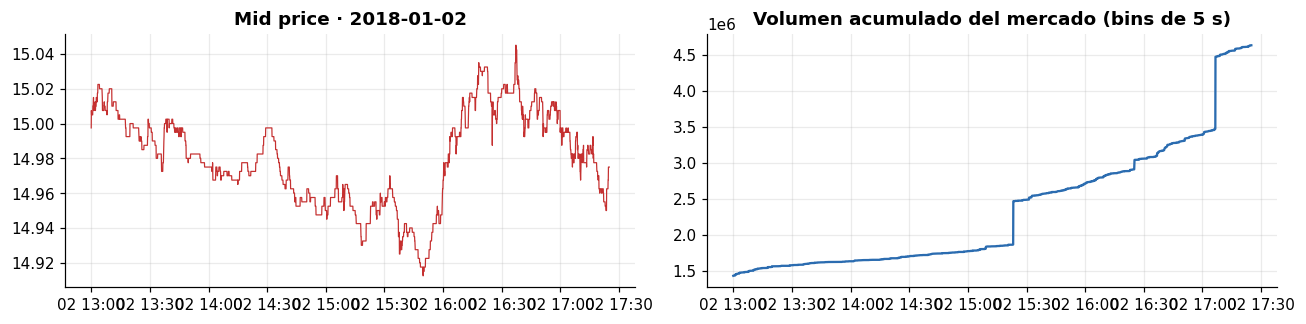

In [2]:
display(pd.DataFrame({s: {"días": len(d), "bins de 5 s por día": f"{min(map(len, d.values()))}-{max(map(len, d.values()))}"}
                      for s, d in DATA.items()}).T)
e1_day = next(iter(train)); e1_df = train[e1_day]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.2))
a1.plot(e1_df.index, (e1_df.ask1 + e1_df.bid1) / 2, color=lab.MID, lw=.8); a1.set_title(f"Mid price · {e1_day}")
a2.plot(e1_df.index, e1_df.cumvol, color=lab.MKT); a2.set_title("Volumen acumulado del mercado (bins de 5 s)")
fig.tight_layout(); plt.show()

---
# Entorno

> 🔧 **Bloque modificado · Ej. 1** — `BestExecutionEnv` está completo en `common/env.py`. Cada hueco del LAB tiene su implementación:

| Hueco del LAB | Implementación | Qué hace |
|---|---|---|
| Parámetros y episodio | `_generate_episode_params`, `_generate_episode`, `reset` | Elige al azar entre 400 y 600 pasos de 5 s, una orden del 7,5-12,5 % de esos pasos, el día y la hora de inicio |
| Observación | `observation_builder` | `s = [T, V]`: tiempo y volumen restantes en tanto por uno |
| VWAP de mercado y del algoritmo | `_compute_market_vwap`, `_compute_algo_vwap` | Precio medio ponderado por volumen del episodio y de nuestras compras |
| Recompensa | `_compute_reward` → `rewards.Default` | La del LAB: (VWAP del episodio − precio pagado) / VWAP si compra, 0 si espera |
| Parada | `_compute_stop_conditions`, `_compute_done` | Termina al completar la orden o al agotar el tiempo |
| Acciones | `_do_nothing`, `_agg_action`, `action_sample` | Esperar o comprar 1 título al `ask1`. Al explorar se compra con probabilidad p = n/N |

In [3]:
codigo(BestExecutionEnv.step)
# Intercambio real agente ↔ entorno con 6 acciones elegidas a mano
e1_env = BestExecutionEnv(train, reward=rw.Default(), seed=123, obs_mode="TV")
e1_s, e1_rows = e1_env.reset(day=e1_day, start_pos=60, n_bins=500, vol_care=50), []
for e1_a in [1, 0, 0, 1, 0, 1]:
    e1_ask = float(e1_env._ask[e1_env.state_pos])
    e1_s1, e1_r, e1_done, _ = e1_env.step(e1_a)
    e1_rows.append({"T": e1_s[0], "V": e1_s[1], "acción": "comprar" if e1_a else "esperar",
                    "precio": e1_ask if e1_a else np.nan, "recompensa": e1_r, "T'": e1_s1[0], "V'": e1_s1[1]})
    e1_s = e1_s1
display(pd.DataFrame(e1_rows))

**`BestExecutionEnv.step`** · `notebooks/common/env.py`

```python
def step(self, action: int):
    """Evalúa la acción, calcula la recompensa y devuelve (obs, r, done, info)."""
    market_vwap = self._compute_market_vwap()
    act_fn = self.actions_fn.get(int(action))
    if act_fn is None:
        raise ValueError(f"Invalid action {action}. Valid actions {list(self.actions_fn)}")
    self.reward.before_step(self, int(action))
    reward = act_fn()
    self.actions_hist.append(int(action))
    self.market_vwap_hist.append(market_vwap)
    self.reward_hist.append(reward)
    self.state_pos += 1
    done = self._compute_done()
    if done:
        reward += self._compute_done_reward()
        return None, reward, done, {}
    return self.observation_builder(), reward, done, {}
```

,T,V,acción,precio,recompensa,T',V'
0,1.000,1.00,comprar,15.025,-0.002,0.998,0.98
1,0.998,0.98,esperar,NaN,0.000,0.996,0.98
2,0.996,0.98,esperar,NaN,0.000,0.994,0.98
3,0.994,0.98,comprar,15.025,-0.002,0.992,0.96
4,0.992,0.96,esperar,NaN,0.000,0.990,0.96
5,0.990,0.96,comprar,15.025,-0.002,0.988,0.94


---
<center><h2>TWAP</h2></center>

<center>
<p style="width:80%">
El <b><i>time weighted average price</i></b> (TWAP) es un algoritmo tradicional de negociación basado en el precio medio ponderado por el tiempo, utilizado normalmente para la ejecución de órdenes grandes para reducir el impacto de mercado. Básicamente, se trocea la orden de manera que ejecute las órdenes en un tiempo equidistante durante el tiempo de ejecución seleccionado por el cliente. Puede ser fácil adivinar el patrón de negociación de la estrategia en ejecución si sus órdenes no se modifican de una manera especial, por lo que los parámetros se pueden ajustar o alterar para hacer que la estrategia sea más difícil de rastrear. Las soluciones más comunes son la aleatorización del tamaño de las órdenes y/o el tiempo de envío entre cada una de ellas. Es posible limitar la cantidad para que no exceda un porcentaje definido del volumen de participación, o también evitar agresiones de más de una posición del libro. Esto nos ayuda a minimizar el impacto de las estrategias en el mercado.
</p>  
<p style="width:80%">
Para el objetivo del taller, se pide a los participantes implementar un TWAP sin la necesidad de realizar ninguna modificación. El agente TWAP ha de trocear y ejecutar las órdenes hijas de la orden CARE equidistantes en el tiempo, sin necesidad de incorporar mecanismos para evitar su detección.
</p>

> 🔧 **Bloque modificado · Ej. 1** — TWAP determinista: compra cuando lo que queda por comprar va igual o por delante de lo que queda de tiempo (`V ≥ T`). Así reparte las hijas de forma equidistante y sin mecanismos anti-detección.

**`TWAPAgent.act`** · `notebooks/common/agents.py`

```python
def act(self, s) -> int:
    return int(s[1] >= s[0] - 1e-9)
```

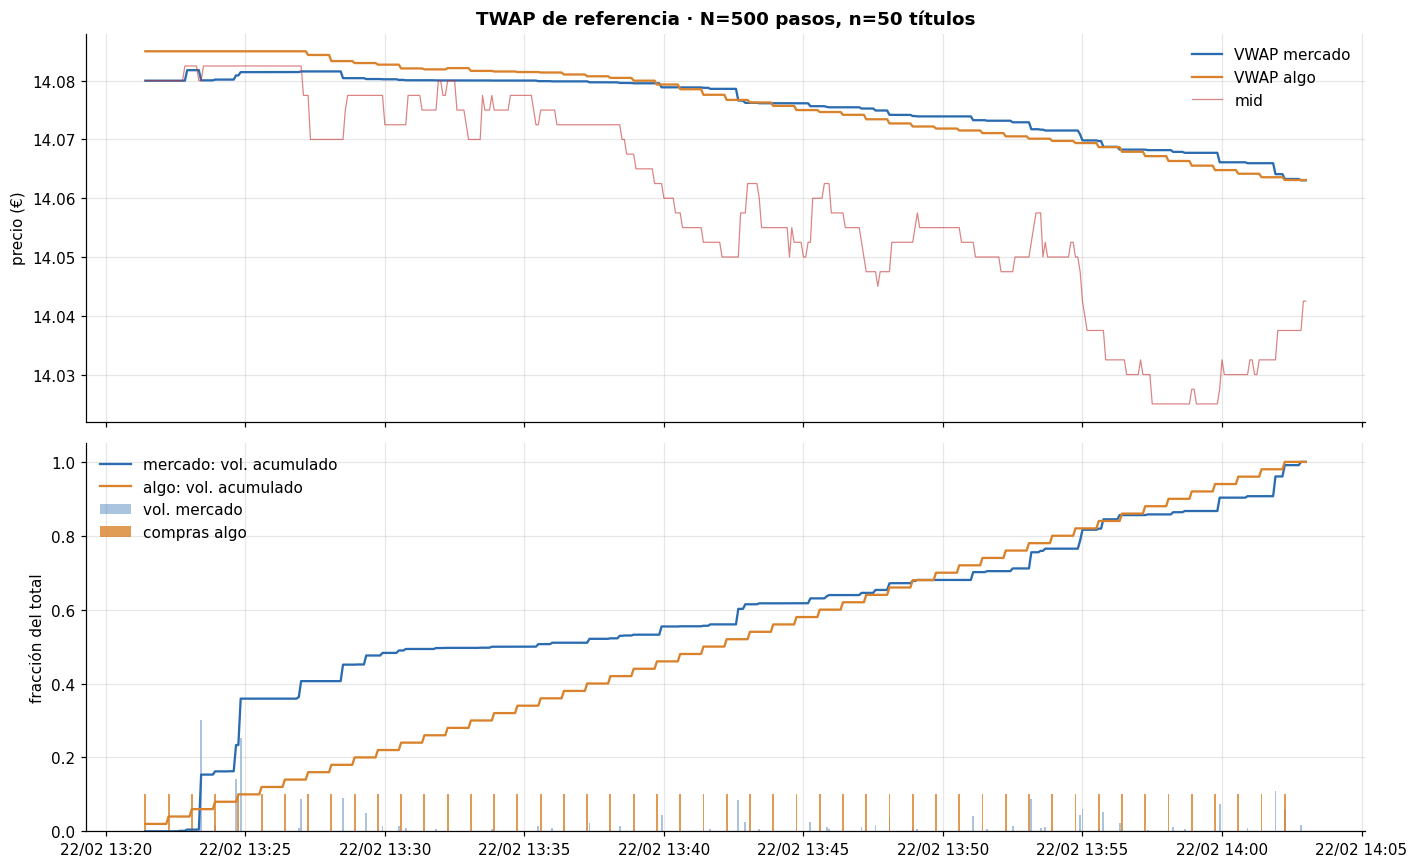

In [4]:
codigo(TWAPAgent.act)
e1_tw = BestExecutionEnv(train, reward=rw.Default(), seed=1, obs_mode="TV")
pr.run_episode(e1_tw, TWAPAgent(), GRID[4])
pl.plot_results(e1_tw, title=f"TWAP de referencia · N={e1_tw.episode_bins} pasos, n={e1_tw.vol_care} títulos"); plt.show()

------------------
<center><h2>Parametrización del Problema</h2></center>

<center>
<p style="width:80%">
Una vez definido el entorno que vamos a utilizar como simulador de mercado, necesitamos definir el agente que va a encargarse de aprender a ejecutar las órdenes CARE. El agente es el <b><i>cerebro</i></b> del sistema y puede tener, o no, inteligencia artificial implementada. Por ejemplo, la clase TWAP anteriormente implementada depende únicamente de una regla determinista. Por otro lado, los algoritmos vistos durante el bloque de Aprendizaje por Refuerzo dependerán de la construcción de un modelo de aprendizaje y, por tanto, requerirán la parametrización de estos. Los parámetros e hiperparámetros del modelo dependerán de la aproximación y modelo que elijamos.
</p>
</center>

---
<center >
<p style="width:80%">
    <b>Epsilon</b>: Parámetro de exploración para los algoritmos basados en funciones valor (por ejemplo, los deep Q-learning). Puede tomar valores entre [0,1].
</p> 
</center>
<center>
<p style="width:80%">
    <b>Min Epsilon</b>: Valor mínimo del epsilon por si se quiere dejar aleatoriedad durante procesos de entrenamiento muy largos en los que el <b>epsilon</b> decaería hasta cero.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Epsilon_decay</b>: Valor numérico mediante el cual se reduce el valor de epsilon cada determinado número de episodios.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Gamma</b>: Término de descuento para el cálculo de los retornos acumulados con descuento. Dado que nuestro MDP se define con tareas episódicas gamma podrá tomar valores en el intervalo [0,1].
</p> 
</center>
<center>
<p style="width:80%">
    <b>Alpha</b>: Step-size, término indicando el tamaño de las actualizaciones durante el aprendizaje. Dado que nuestro problema es no estacionario (el sistema evoluciona en el tiempo) el alpha será un valor estático o adaptativo pero nunca un valor que decaiga a cero con el tiempo.
</p> 
</center>

<center>
<p style="width:80%">
    <b>Buffer Size</b>: Tamaño de la memoria encargada de obtener un conjunto de datos que aproximadamente sea independiente e idénticamente distribuido (i.i.d).
</p> 
</center>

---
<center>
<p style="width:80%">
<b>*Nota*</b>: Los parámetros que definen la arquitectura de la red dependen de lo flexible y compleja que se construyan en los agentes. Los agentes ofrecidos para el taller mantienen la filosofía del mismo y se mantendrán sencillos.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Batch size</b>: Tamaño de los paquetes de datos que se envían al modelo durante su aprendizaje.
</p> 
</center>

<center>
<p style="width:80%">
    <b>Hidden_neurons</b>: Número de neuronas en las capas ocultas de los modelos.
</p> 
</center>

---
<center>
<p style="width:80%">
    <b>Nepisodes</b>: Número de sesiones de trading (episodios) que se van a realizar para el entrenamiento del modelo.
</p> 
</center>
<center>
<p style="width:80%">
    <b>N_log</b>: Valor numérico indicando cada cuántos episodios se realiza un log de la situación actual del aprendizaje.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Learn_after</b>: Valor numérico indicando cada cuántos steps se realiza un aprendizaje por parte de las redes.
</p> 
</center>
<center>
<p style="width:80%">
    <b>Update_target_after</b>: Valor numérico indicando cada cuántos steps se copian los pesos de la red primary a la red target.
</p> 
</center>

> 🔧 **Bloque modificado · Ej. 1** — valores elegidos. En el Ej. 1 no se busca una lógica de negocio todavía; la parametría se motiva en el Ej. 2.

In [5]:
epsilon, min_epsilon = 1.0, 0.02
gamma, alpha = 0.99, 1e-3
buffer_size, batch_size, hidden_neurons = 50_000, 64, 64
nepisodes = 4000
epsilon_decay = (epsilon - min_epsilon) / (0.5 * nepisodes)
learn_after, update_target_after = batch_size, 10 * batch_size
SEED, fill_episodes, eval_every = 0, 25, 250
display(pd.DataFrame([
    ("epsilon → min_epsilon", f"{epsilon} → {min_epsilon}", "explorar todo al principio y no llegar nunca a 0"),
    ("epsilon_decay", f"{epsilon_decay:.2e}", "lineal: llega al mínimo a mitad del entrenamiento"),
    ("gamma", gamma, "valor por defecto del LAB"),
    ("alpha", alpha, "constante, porque el problema no es estacionario"),
    ("buffer_size / batch_size", f"{buffer_size} / {batch_size}", "unos 100 episodios en memoria"),
    ("hidden_neurons", hidden_neurons, "red 2 → 64 → 64 → 2"),
    ("nepisodes", nepisodes, "con validación cada 250 episodios"),
    ("learn_after / update_target_after", f"{learn_after} / {update_target_after}", "proporción del LAB: la red objetivo cada 10 aprendizajes"),
], columns=["parámetro", "valor", "por qué"]).set_index("parámetro"))

,valor,por qué
parámetro,,
epsilon → min_epsilon,1.0 → 0.02,explorar todo al principio y no llegar nunca a 0
epsilon_decay,4.90e-04,lineal: llega al mínimo a mitad del entrenamiento
gamma,0.99,valor por defecto del LAB
alpha,0.001,"constante, porque el problema no es estacionario"
buffer_size / batch_size,50000 / 64,unos 100 episodios en memoria
hidden_neurons,64,red 2 → 64 → 64 → 2
nepisodes,4000,con validación cada 250 episodios
learn_after / update_target_after,64 / 640,proporción del LAB: la red objetivo cada 10 ap...


<center><h3>Inicialización del agente</h3></center>

> 🔧 **Bloque modificado · Ej. 1** — se crea el `DDQNAgent` de `common/agents.py` (Double DQN en PyTorch). La semilla se fija **antes** de crear la red: en una misma máquina el entrenamiento se repite igual, aunque con otra versión de PyTorch el modelo elegido puede variar. Como en el LAB, la primera acción de cada episodio es siempre comprar (`force_first_buy`), así que el error mínimo posible es de unos 0,9 títulos.

In [6]:
pr.set_seeds(SEED)
env = BestExecutionEnv(train, look_back=60, reward=rw.Default(), seed=SEED, obs_mode="TV")
agent = DDQNAgent(env, gamma=gamma, epsilon=epsilon, alpha=alpha, batch_size=batch_size,
                  buffer_size=buffer_size, hidden_neurons=hidden_neurons, seed=SEED, force_first_buy=True)
print(agent.primary_model)

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)


<center><h3>Recolección de los Episodios para el Buffer</h3></center>
<center>
<p style="width:80%">
Antes de empezar el entrenamiento, para que el modelo tenga experiencias de las que aprender y poder tomar acciones greedy con cierto criterio ha de tener muestras para entrenar. Para ello vamos a llenar el buffer con experiencias siguiendo una política estocástica con el objetivo de explorar el entorno inicialmente.
</p>

> 🔧 **Bloque modificado · Ej. 1** — el buffer se llena con 25 episodios completos en lugar de `buffer_size` pasos sueltos. Así cada experiencia pertenece a un episodio terminado.

In [7]:
e1_steps = pr.fill_buffer(agent, env, n_episodes=fill_episodes)
print(f"Buffer inicial: {len(agent.buffer)} experiencias de {fill_episodes} episodios")

Buffer inicial: 12202 experiencias de 25 episodios


#### Train Algo

> 🔧 **Bloque modificado · Ej. 1** — es el mismo bucle del LAB, `act → step → experience → learn / update_target` (código debajo), con dos añadidos: cada 250 episodios se evalúa sin exploración sobre `val` y se guarda el mejor modelo y el último. El criterio para elegir, en este orden: más órdenes completas, menos títulos pendientes y mejor slippage. Los checkpoints van a una carpeta temporal para no tocar `results/`.

In [8]:
codigo(pr.train, desde="for episode in range", hasta="if verbose and log_every")
codigo(DDQNAgent.learn)

**`train`** · `notebooks/common/protocol.py`

```python
for episode in range(start_episode, start_episode + nepisodes):
    s = env.reset()
    step, cum_reward, dis_cum_reward = 0, 0.0, 0.0
    while True:
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        learn_counter += 1
        cum_reward += r
        dis_cum_reward += agent.gamma ** step * r
        s = s1
        step += 1
        if not learn_counter % learn_after:
            mse = agent.learn()
        if not learn_counter % update_target_after:
            agent.update_target()
        if done:
            exploration.on_episode_end(agent, episode)
            ep_rows.append({"episode": episode, "steps": step, "reward": cum_reward,
                            "disc_reward": dis_cum_reward, "mse": mse, "epsilon": agent.epsilon,
                            "completed": env.exec_vol >= env.vol_care, "N": env.episode_bins, "n": env.vol_care})
            break
```

**`DDQNAgent.learn`** · `notebooks/common/agents.py`

```python
def learn(self) -> float:
    """Un paso de descenso por gradiente sobre un batch; devuelve el MSE."""
    if len(self.buffer) < self.batch_size:
        return float("nan")
    batch = self.sample()
    s = torch.as_tensor(np.array([b[0] for b in batch]), dtype=torch.float32)
    a = torch.as_tensor([b[1] for b in batch], dtype=torch.int64)
    r = torch.as_tensor([b[2] for b in batch], dtype=torch.float32)
    not_done = torch.as_tensor([b[3] is not None for b in batch])
    s1 = torch.zeros_like(s)
    if not_done.any():
        s1[not_done] = torch.as_tensor(np.array([b[3] for b in batch if b[3] is not None]), dtype=torch.float32)

    with torch.no_grad():
        best_next = self.primary_model(s1).argmax(dim=1, keepdim=True)  # la primaria elige...
        q_next = self.target_model(s1).gather(1, best_next).squeeze(1)  # ...y la target evalúa
        target = r + self.gamma * q_next * not_done.float()

    q = self.primary_model(s).gather(1, a.unsqueeze(1)).squeeze(1)
    loss = self.loss_fn(q, target)
    self.optimizer.zero_grad()
    loss.backward()
    self.optimizer.step()
    return float(loss.item())
```

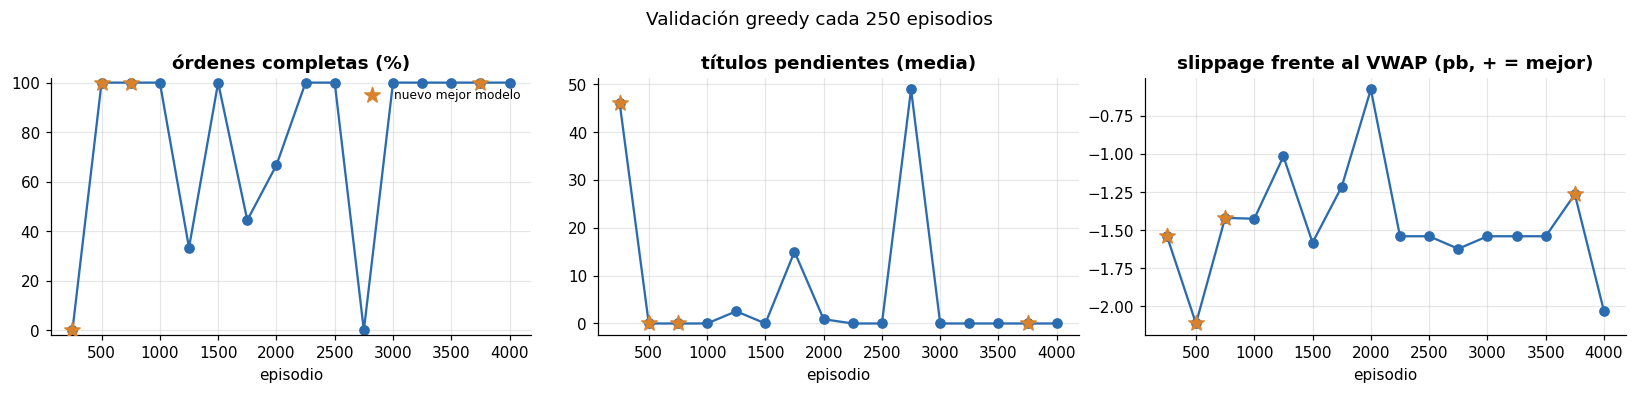

4000 episodios entrenados · modelo elegido con validación: episodio 3750


In [9]:
import tempfile
e1_ckpt = Path(tempfile.mkdtemp()) / "ej1_ddqn"
e1_grid_val = pr.make_grid(DATA["val"], n_days=3, seed=0)
ep, ev = pr.train(agent, env, nepisodes, ex.LinearDecay(epsilon, min_epsilon, epsilon_decay),
                  learn_after=learn_after, update_target_after=update_target_after, log_every=500,
                  eval_data=DATA["val"], eval_grid=e1_grid_val, eval_every=eval_every,
                  eval_reward=rw.Default(), checkpoint=e1_ckpt, checkpoint_metric="execution", verbose=False)
pl.plot_validation(ev, title="Validación greedy cada 250 episodios"); plt.show()
e1_best = agent.load(f"{e1_ckpt}_best.pt"); agent.set_trainable(False)
print(f"{len(ep)} episodios entrenados · modelo elegido con validación: episodio {e1_best['episode']}")

#### Plot Results

> 🔧 **Bloque modificado · Ej. 1** — se evalúa sin exploración, frente al TWAP, sobre la **rejilla**: 27 órdenes fijas de train (3 días × N ∈ {400, 500, 600} pasos × n/N ∈ {7,5; 10; 12,5} %). El **error** es la máxima separación, en títulos, entre lo comprado y el plan TWAP. Test se mira una sola vez, ya con el modelo elegido.

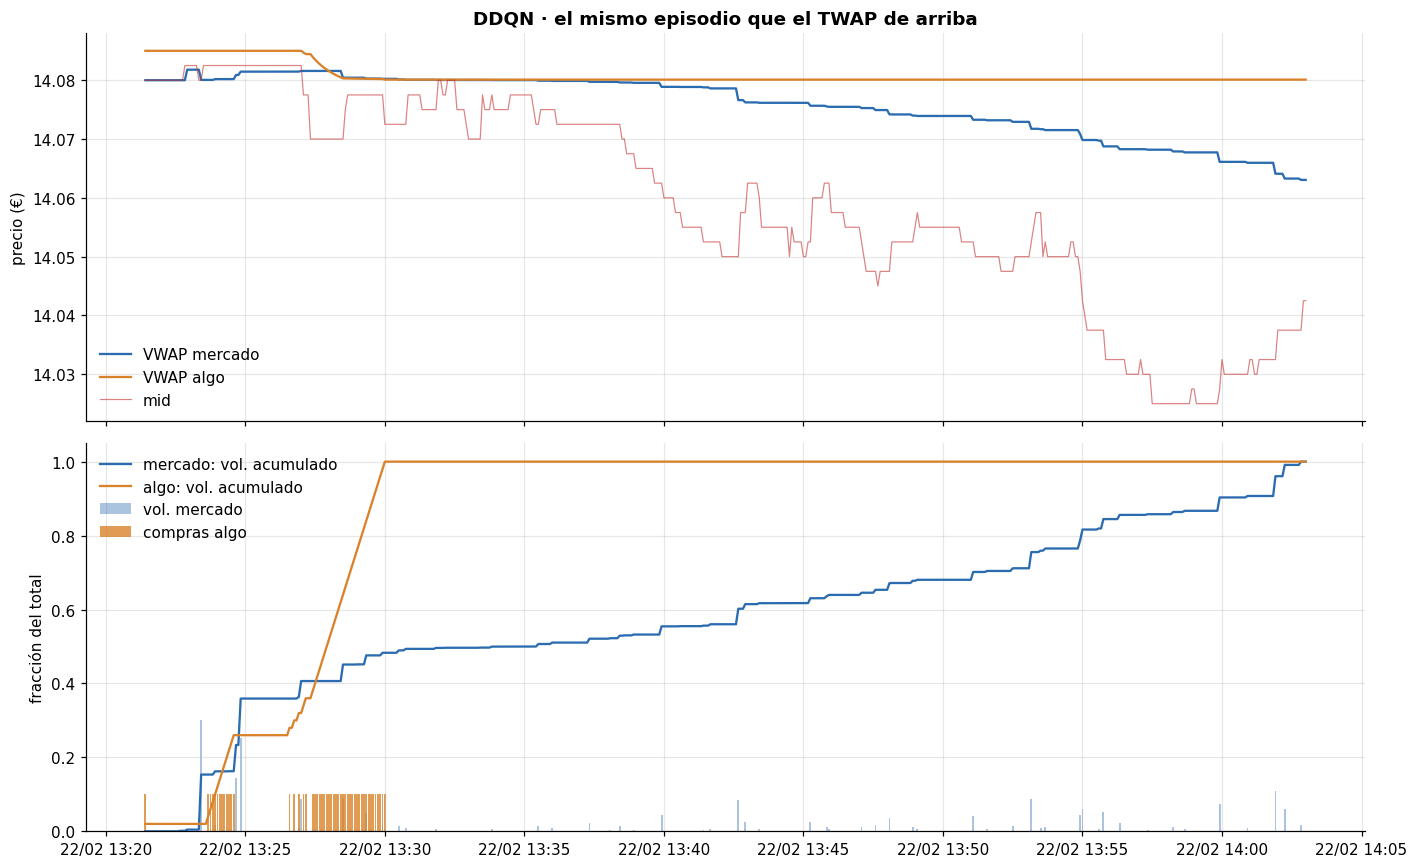

In [10]:
e1_res = pr.evaluate(agent, train, GRID, reward=rw.Default(), obs_mode="TV")
e1_twap = pr.evaluate(TWAPAgent(), train, GRID, reward=rw.Default(), obs_mode="TV", with_twap=False)
e1_test = pr.evaluate(agent, DATA["test"], pr.make_grid(DATA["test"], n_days=3, seed=0), reward=rw.Default(), obs_mode="TV")
kpis([("Órdenes completas (train)", f"{int(e1_res.completed.sum())}/{len(e1_res)}", f"test: {int(e1_test.completed.sum())}/{len(e1_test)}"),
      ("Acaba al … del plazo", f"{100 * e1_res.t_fin.mean():.0f} %", f"TWAP: {100 * e1_twap.t_fin.mean():.0f} %"),
      ("Error frente al plan TWAP", f"{e1_res.max_err.mean():.2f}", f"TWAP: {e1_twap.max_err.mean():.2f} títulos"),
      ("Slippage medio", f"{e1_res.slippage_bps.mean():+.2f} pb", f"TWAP: {e1_twap.slippage_bps.mean():+.2f} pb")],
     title="Ej. 1 · DDQN con la recompensa del LAB (27 órdenes fijas)")
e1_ev = BestExecutionEnv(train, seed=1, reward=rw.Default(), obs_mode="TV"); agent.env = e1_ev
pr.run_episode(e1_ev, agent, GRID[4])
pl.plot_results(e1_ev, title="DDQN · el mismo episodio que el TWAP de arriba"); plt.show()

> 🔧 **Bloque modificado · Ej. 1** — la curva del LAB (media móvil de 20 episodios de la recompensa) junto a ε, sacadas del registro del entrenamiento.

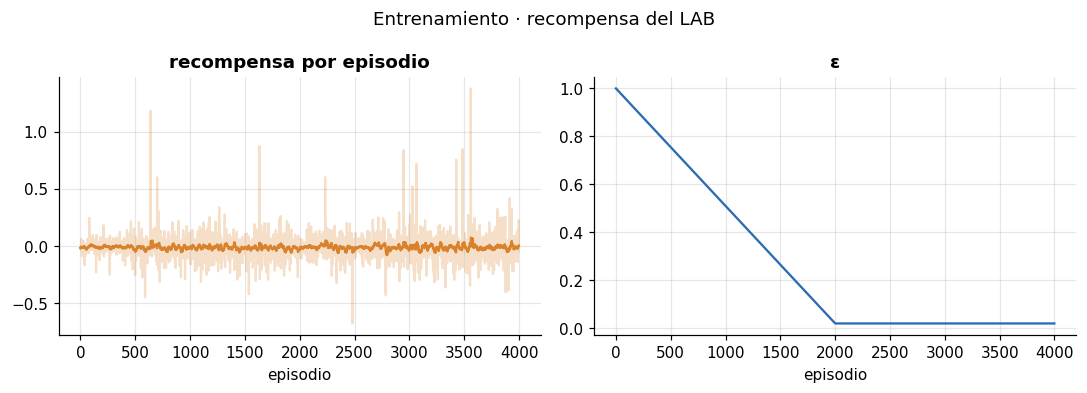

In [11]:
pl.plot_training(ep, title="Entrenamiento · recompensa del LAB"); plt.show()

In [12]:
display(Markdown(lab.es(
    f"**Conclusión.** El circuito completo funciona: datos → episodio → `[T, V]` → acción → recompensa → buffer → "
    f"Double DQN → validación → mejor modelo → evaluación sin exploración. El agente completa "
    f"{int(e1_res.completed.sum())}/{len(e1_res)} órdenes, pero acaba al {100 * e1_res.t_fin.mean():.0f} % del plazo "
    f"(TWAP: {100 * e1_twap.t_fin.mean():.0f} %) y paga {e1_res.slippage_bps.mean():+.2f} pb frente a "
    f"{e1_twap.slippage_bps.mean():+.2f} del TWAP. La recompensa del LAB compara cada compra con el VWAP de *todo* el "
    f"episodio, que `[T, V]` no permite anticipar, y no dice nada del reparto en el tiempo; por eso el momento de compra "
    f"que aprende la red es arbitrario. Que reparta es el Ej. 2. Detalle: [`ej1_execution_lab.ipynb`](ej1_execution_lab.ipynb).")))

**Conclusión.** El circuito completo funciona: datos → episodio → `[T, V]` → acción → recompensa → buffer → Double DQN → validación → mejor modelo → evaluación sin exploración. El agente completa 27/27 órdenes, pero acaba al 21 % del plazo (TWAP: 98 %) y paga -4,67 pb frente a -1,77 del TWAP. La recompensa del LAB compara cada compra con el VWAP de *todo* el episodio, que `[T, V]` no permite anticipar, y no dice nada del reparto en el tiempo; por eso el momento de compra que aprende la red es arbitrario. Que reparta es el Ej. 2. Detalle: [`ej1_execution_lab.ipynb`](ej1_execution_lab.ipynb).

# Ejercicio 2 · Un TWAP aprendido por recompensas

| | |
|---|---|
| **Qué pide** | Cambiar la recompensa para que el agente replique un TWAP en cualquier día, hora, duración (400-600 pasos) y tamaño de la orden, y motivar la parametría (γ, buffer…). |
| **Qué hacemos** | Mismo estado `[T, V]`; recompensa = −distancia al plan TWAP en cada paso + cierre por los pasos que faltan; γ = 0,9, buffer 10.000, aprender cada 8 pasos, elegidos con barridos de 3 semillas. |
| **Resultado** | Error de **0,90 títulos**, igual que el TWAP, y **27/27 órdenes completas** en la rejilla de train. |

Detalle en [ej2_twap_recompensas.ipynb](ej2_twap_recompensas.ipynb) y en las decisiones D-2.1 a D-2.7 de [DECISIONES.md](../docs/DECISIONES.md).

## 2.1 El estado: `[T, V]`, sin cambios

Tiempo y volumen restantes en tanto por uno. El TWAP es la diagonal `V = T` y la desviación al plan es `n·(T − V)`: el estado basta para predecir la recompensa y, normalizado, todos los días, duraciones y tamaños son el mismo problema. Sin variables de mercado: un TWAP no las usa.

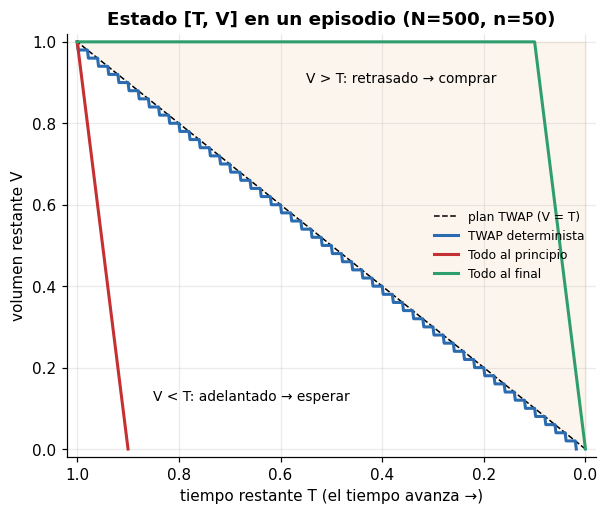

In [13]:
class e2_Policy:
    """Política fija con la interfaz de protocol.run_episode."""
    def __init__(self, fn, env): self.fn, self.env = fn, env
    def act(self, s): return self.fn(self.env, s)
    def set_trainable(self, train=False): pass

e2_POL = {"TWAP determinista": (lambda e, s: int(s[1] >= s[0] - 1e-9), lab.MKT),
          "Todo al principio": (lambda e, s: 1, lab.KO),
          "Todo al final":     (lambda e, s: int(e.episode_bins - e.state_pos <= e.vol_care - e.exec_vol), lab.OK),
          "Aleatoria (p = n/N)": (lambda e, s: e.action_sample(), lab.GREY)}

e2_cfg = GRID[13]
fig, ax = plt.subplots(figsize=(6.2, 5))
ax.fill_between([0, 1], [0, 1], [1, 1], color=lab.ALGO, alpha=0.08)
ax.text(0.55, 0.9, "V > T: retrasado → comprar", fontsize=9); ax.text(0.85, 0.12, "V < T: adelantado → esperar", fontsize=9)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="plan TWAP (V = T)")
for name in ["TWAP determinista", "Todo al principio", "Todo al final"]:
    fn, col = e2_POL[name]
    e2_env = BestExecutionEnv(train, seed=0); s = e2_env.reset(**{k: e2_cfg[k] for k in ("day", "start_pos", "n_bins", "vol_care")})
    S, done = [s], False
    while not done:
        s, _, done, _ = e2_env.step(e2_Policy(fn, e2_env).act(s)); S.append([e2_env.time_left(), e2_env.vol_left()])
    S = np.array(S); ax.plot(S[:, 0], S[:, 1], color=col, lw=2, label=name)
ax.set_xlim(1.02, -0.02); ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("tiempo restante T (el tiempo avanza →)"); ax.set_ylabel("volumen restante V")
ax.set_title(f"Estado [T, V] en un episodio (N={e2_cfg['n_bins']}, n={e2_cfg['vol_care']})"); ax.legend(fontsize=8, loc="center right")
plt.show()

## 2.2 La recompensa: seguir el plan, con cierre

> 🔧 **Bloque modificado · Ej. 2** — `_compute_reward` y `_compute_done_reward`: el slippage frente al VWAP del LAB se sustituye por `TrackingCierre`.

En cada paso, $r_t = -\min(|e_{t+1} - (t+1)\,n/N|,\ c)/c \in [-1, 0]$ con c = 20 títulos: densa, local y sin dictar la acción. Si la orden acaba antes de N, el cierre cobra los pasos que faltan descontados con γ; sin él, terminar pronto apaga la penalización. Políticas fijas en los 27 episodios: la recompensa del LAB premia «todo al final»; sin cierre, «todo al principio» queda cerca del TWAP (c = 5); con cierre, el atajo se hunde.

In [14]:
codigo(rw.Tracking.step, rw.TrackingCierre.done)

e2_REW = {"Default (LAB)": lambda: rw.Default(),
          "Seguimiento sin cierre": lambda: rw.Tracking(clip=5.0),
          "Seguimiento con cierre": lambda: rw.TrackingCierre(gamma=1.0, clip=5.0)}
e2_rows = []
for pname, (fn, _) in e2_POL.items():
    for rname, make in e2_REW.items():
        e2_env = BestExecutionEnv(train, reward=make(), seed=0); pol = e2_Policy(fn, e2_env)
        for cfg in GRID:
            G = pr.run_episode(e2_env, pol, cfg)
            e2_rows.append({"política": pname, "recompensa": rname, "G": G, **pr.episode_metrics(e2_env, G)})
e2_ref = pd.DataFrame(e2_rows)
e2_tab = e2_ref.pivot_table(index="política", columns="recompensa", values="G").reindex(list(e2_POL))[list(e2_REW)]
e2_tab.insert(0, "error máx. (títulos)", e2_ref[e2_ref.recompensa == "Default (LAB)"].groupby("política").max_err.mean())
display(Markdown("**Retorno medio sin descontar en la rejilla · más alto = preferido por la recompensa** (recorte c = 5, el de partida: con él se ve el atajo)"))
display(e2_tab.style.format("{:.3f}", subset=["Default (LAB)"]).format("{:.1f}", subset=list(e2_tab.columns[[0, 2, 3]]))
        .highlight_max(axis=0, subset=list(e2_REW), color="#2F9E6E44"))

**`Tracking.step`** · `notebooks/common/rewards.py`

```python
def step(self, env, price, vol):
    d = env.exec_vol - plan_target(env, self.horizon)
    return -min(abs(d), self.clip) / self.clip
```

**`TrackingCierre.done`** · `notebooks/common/rewards.py`

```python
def done(self, env):
    r = super().done(env)
    N, n, t = env.episode_bins, env.vol_care, env.state_pos
    if t >= N:
        return r
    k = np.arange(t + 1, N + 1)
    plan = np.minimum(n, k * n / (self.horizon * N))
    pen = -np.minimum(np.abs(env.exec_vol - plan), self.clip) / self.clip
    return r + float((self.gamma ** np.arange(1, len(k) + 1) * pen).sum())
```

**Retorno medio sin descontar en la rejilla · más alto = preferido por la recompensa** (recorte c = 5, el de partida: con él se ve el atajo)

recompensa,error máx. (títulos),Default (LAB),Seguimiento sin cierre,Seguimiento con cierre
política,,,,
TWAP determinista,0.9,-0.009,-43.0,-43.7
Todo al principio,44.7,-0.013,-47.6,-471.0
Todo al final,44.7,0.020,-471.0,-471.0
Aleatoria (p = n/N),7.3,-0.011,-254.9,-272.5


## 2.3 Entrenamiento

DDQN del Ej. 1, 300 episodios (+25 aleatorios), ε lineal 1 → 0,05 en 150, evaluación greedy cada 25. Registros guardados: el error baja de 6,8 títulos (episodio 25) a 0,96 (50) y desde el 100 queda en 0,90.

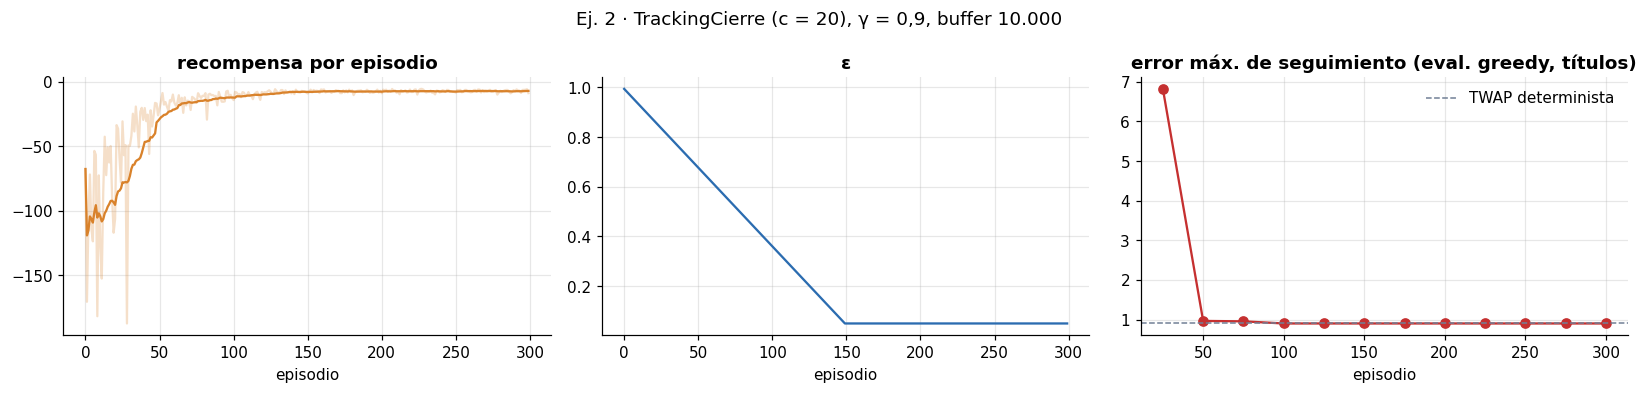

In [15]:
e2_ep, e2_ev = pr.load_df("ej2_train"), pr.load_df("ej2_evals")
fig = pl.plot_training(e2_ep, e2_ev, title="Ej. 2 · TrackingCierre (c = 20), γ = 0,9, buffer 10.000")
fig.axes[2].axhline(pr.load_df("00_twap_grid").max_err.mean(), color=lab.GREY, ls="--", lw=1, label="TWAP determinista")
fig.axes[2].legend(); plt.show()

## 2.4 ¿Se comporta como un TWAP?

Se carga `ej2_ddqn.pt` y se juegan en greedy los 27 episodios de la rejilla (3 días × N ∈ {400, 500, 600} × n/N ∈ {7,5 %, 10 %, 12,5 %}) junto al TWAP determinista; coincide con `ej2_eval_train.csv`.

In [16]:
e2_rew = rw.TrackingCierre(gamma=0.9, clip=20.0)
e2_agent = DDQNAgent(BestExecutionEnv(train, reward=e2_rew, seed=0), gamma=0.9, alpha=1e-3, buffer_size=10_000,
                     hidden_neurons=32)
e2_agent.load(pr.MODELS / "ej2_ddqn.pt"); e2_agent.set_trainable(False)
e2_envs, e2_envs_tw, e2_m = [], [], []
for cfg in GRID:
    e = BestExecutionEnv(train, reward=e2_rew, seed=0); e2_agent.env = e
    G = pr.run_episode(e, e2_agent, cfg); e2_envs.append(e)
    t = BestExecutionEnv(train, seed=0); pr.run_episode(t, TWAPAgent(t), cfg); e2_envs_tw.append(t)
    e2_m.append({"day": str(cfg["day"]), "hora": str(e.episode.index[0])[11:16], **pr.episode_metrics(e, G),
                 "twap_max_err": pr.episode_metrics(t)["max_err"], "twap_mean_err": pr.episode_metrics(t)["mean_err"]})
e2_res = pd.DataFrame(e2_m)
assert np.allclose(e2_res.max_err, pr.load_df("ej2_eval_train").max_err)   # mismo resultado que el CSV guardado
e2_gaps = np.concatenate([np.diff(np.flatnonzero(np.asarray(e.vol_hist) > 0)) / (e.episode_bins / e.vol_care) for e in e2_envs])
kpis([("Error máx. medio", f"{e2_res.max_err.mean():.2f}", f"TWAP determinista: {e2_res.twap_max_err.mean():.2f} títulos"),
      ("Órdenes completas", f"{int(e2_res.completed.sum())}/{len(e2_res)}", f"peor episodio: {e2_res.max_err.max():.2f} títulos"),
      ("Error medio", f"{e2_res.mean_err.mean():.2f}", f"TWAP determinista: {e2_res.twap_mean_err.mean():.2f} títulos"),
      ("Acaba en", f"{e2_res.t_fin.mean():.1%}", "del tiempo, de media"),
      ("Intervalo entre compras", f"{e2_gaps.mean():.2f} ± {e2_gaps.std():.2f}", "en unidades de N/n (TWAP perfecto = 1)")],
     title="DDQN · TrackingCierre en los 27 episodios de train")

Trayectorias sobre la diagonal y política igual a `V = T` en todo el plano. El agente oscila centrado en el plan y la regla va siempre adelantada: de ahí su menor error medio. El 0,90 de error máximo es la compra forzada del paso 0, común a ambos.

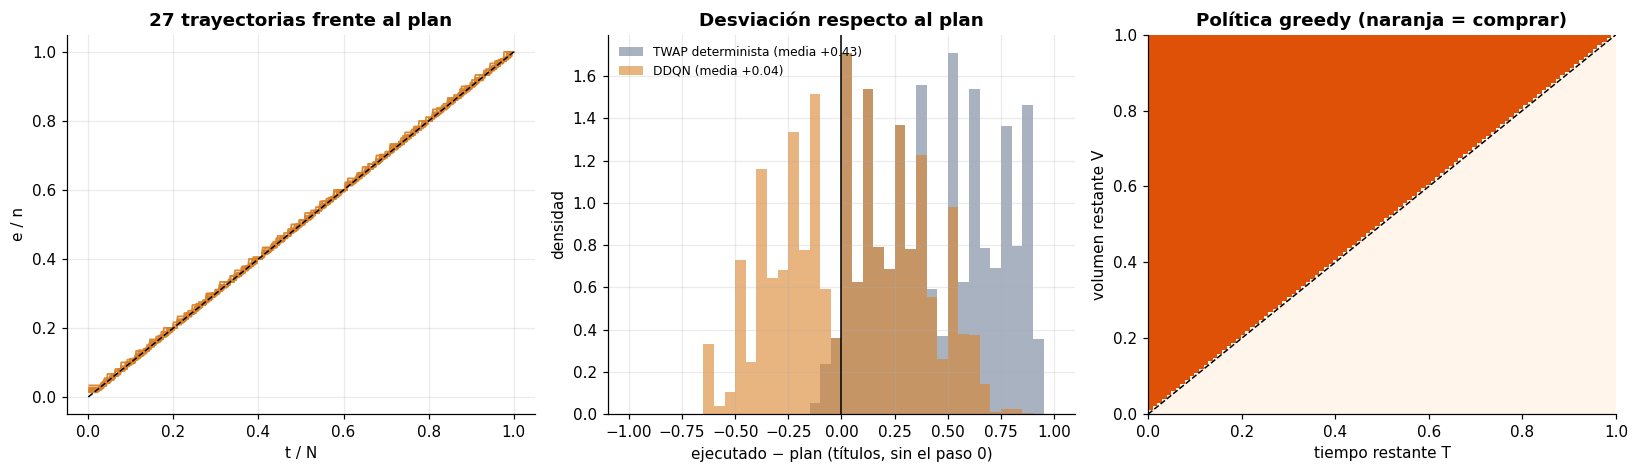

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for e in e2_envs:
    N, n = e.episode_bins, e.vol_care; x = np.arange(1, N + 1) / N
    ax[0].plot(x, pr.trajectory(e) / n, lw=1, alpha=0.6, color=lab.ALGO)
e2_dev = lambda e: (pr.trajectory(e) - np.minimum(e.vol_care, np.arange(1, e.episode_bins + 1) * e.vol_care / e.episode_bins))[1:]
for lst, col, name in [(e2_envs_tw, lab.GREY, "TWAP determinista"), (e2_envs, lab.ALGO, "DDQN")]:
    d = np.concatenate([e2_dev(e) for e in lst])
    ax[1].hist(d, bins=np.linspace(-1, 1, 41), color=col, alpha=0.6, density=True, label=f"{name} (media {d.mean():+.2f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(xlabel="t / N", ylabel="e / n", title="27 trayectorias frente al plan")
ax[1].axvline(0, color="k", lw=1); ax[1].legend(fontsize=8)
ax[1].set(xlabel="ejecutado − plan (títulos, sin el paso 0)", ylabel="densidad", title="Desviación respecto al plan")
e2_T, e2_V = np.meshgrid(np.linspace(0, 1, 101), np.linspace(0, 1, 101))
e2_A = e2_agent.getQs(np.c_[e2_T.ravel(), e2_V.ravel()], e2_agent.primary_model).argmax(axis=1).reshape(e2_T.shape)
ax[2].imshow(e2_A, origin="lower", extent=[0, 1, 0, 1], cmap="Oranges", vmin=0, vmax=1.4, aspect="auto")
ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set(xlabel="tiempo restante T", ylabel="volumen restante V", title="Política greedy (naranja = comprar)")
ax[2].grid(False); fig.tight_layout(); plt.show()

Por día, hora de inicio y duración; cada fila agrupa los tres tamaños de orden. Igual que el TWAP en todas:

In [18]:
e2_cel = e2_res.groupby(["day", "N"]).agg(hora=("hora", "first"), n=("n", lambda x: "/".join(map(str, x))),
                                           error_DDQN=("max_err", "mean"), error_TWAP=("twap_max_err", "mean"),
                                           completas=("completed", "sum"), acaba_en=("t_fin", "mean"))
e2_cel.style.format({"error_DDQN": "{:.2f}", "error_TWAP": "{:.2f}", "acaba_en": "{:.1%}", "completas": "{:.0f}/3"})

Gráfico del LAB en el episodio más largo y con la orden mayor (comparar con `twap_reproduction_dqn.png`): volumen acumulado en escalera diagonal y compras equiespaciadas, aunque el mercado concentre volumen.

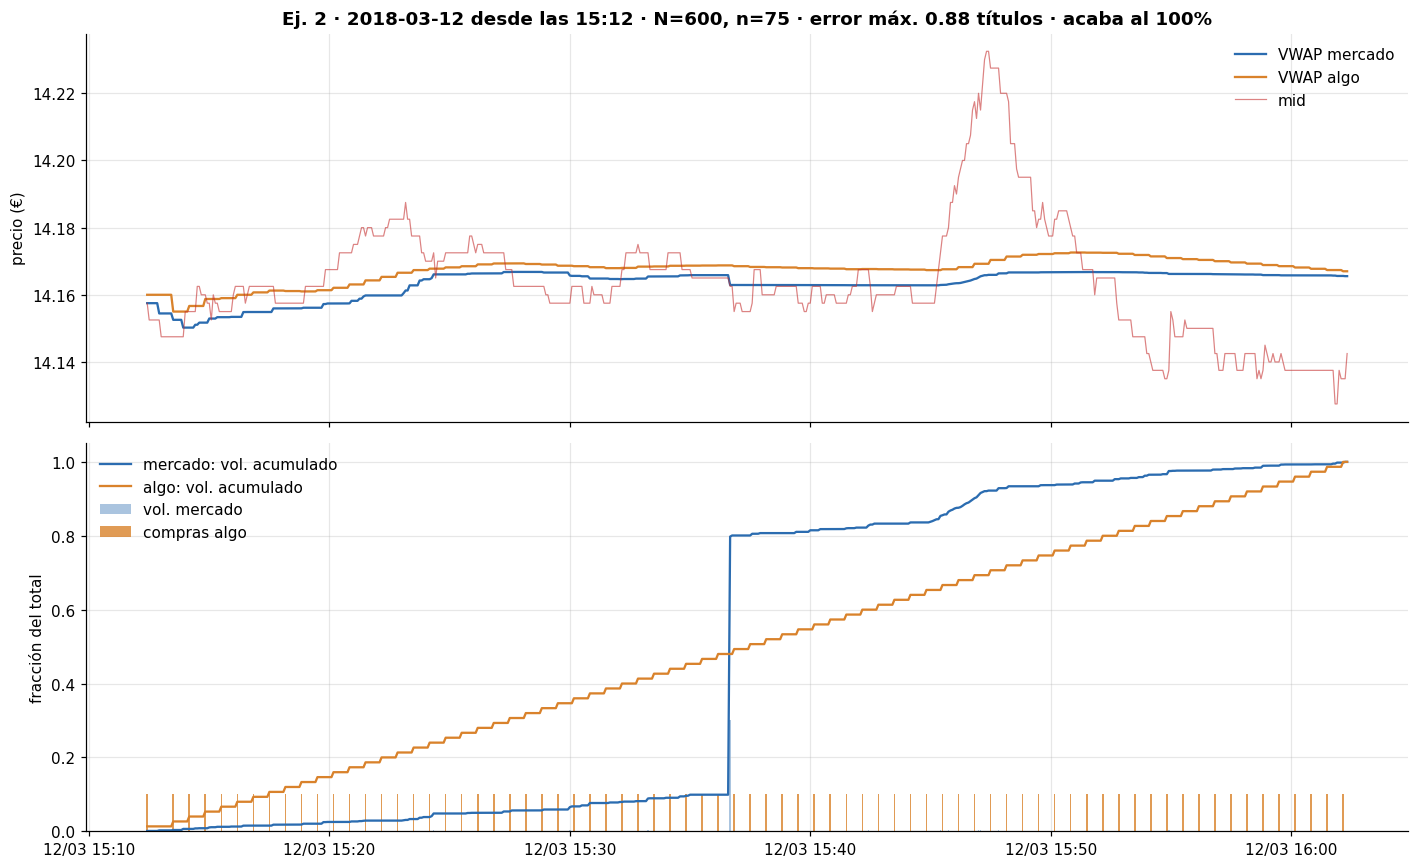

In [19]:
e2_i = 26; e2_e = e2_envs[e2_i]; e2_mi = e2_res.iloc[e2_i]
fig = pl.plot_results(e2_e, title=f"Ej. 2 · {e2_mi.day} desde las {e2_mi.hora} · N={e2_e.episode_bins}, n={e2_e.vol_care} "
                                   f"· error máx. {e2_mi.max_err:.2f} títulos · acaba al {e2_mi.t_fin:.0%}")
plt.show()

## 2.5 Parametría

> 🔧 **Bloque modificado · Ej. 2** — hiperparámetros (entre paréntesis, el Ej. 1): γ = 0,9 (0,99), buffer 10.000 (50.000), aprender/copiar cada 8/1.000 pasos (64/640), red de 32 neuronas (64), 300 episodios con ε 1 → 0,05 en 150 (4000; 0,02 en 2000) y recorte c = 20.

A priori: γ = 0,9 da un horizonte de ~10 pasos, la separación entre compras; con 64/640 hay ~8 actualizaciones por episodio. Se contrasta con barridos de 3 semillas en dos etapas (partida c = 5 y buffer 50.000; luego desde c = 20), que **corrigieron** c (5 → 20) y buffer (50.000 → 10.000).

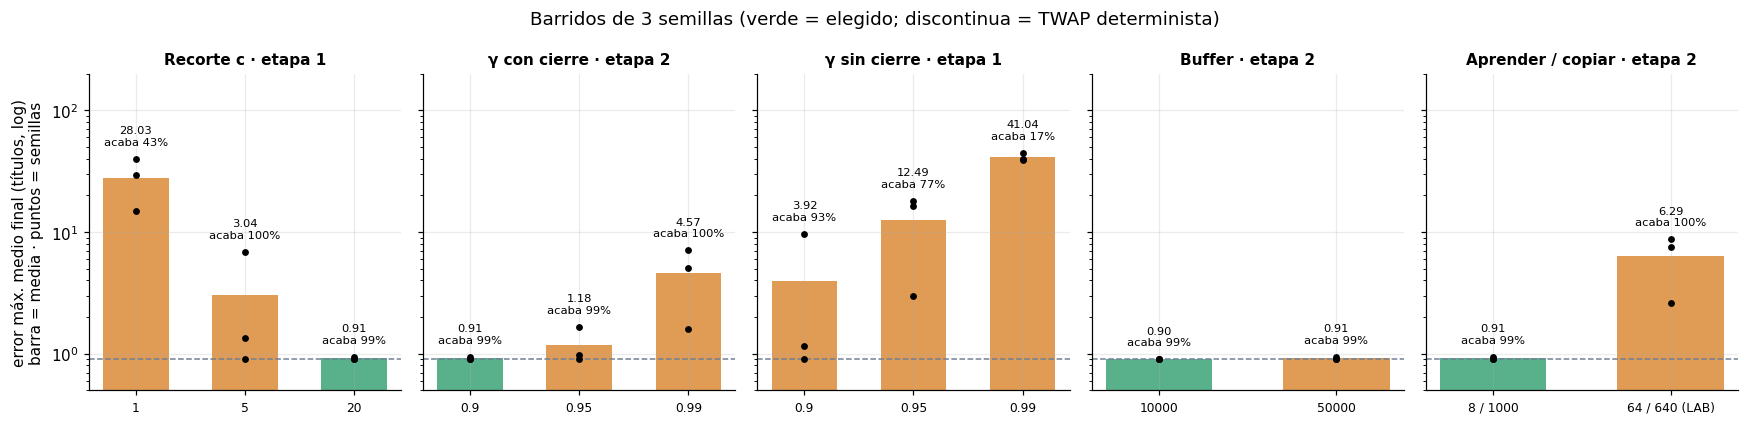

In [20]:
e2_s1, e2_s2 = pr.load_df("ej2_sweeps_etapa1"), pr.load_df("ej2_sweeps_etapa2")
e2_paneles = [("Recorte c · etapa 1", e2_s1, "recorte c", ["1", "5", "20"], "20"),
              ("γ con cierre · etapa 2", e2_s2, "gamma · cierre", ["0.9", "0.95", "0.99"], "0.9"),
              ("γ sin cierre · etapa 1", e2_s1, "gamma · sin cierre", ["0.9", "0.95", "0.99"], None),
              ("Buffer · etapa 2", e2_s2, "buffer", ["10000", "50000"], "10000"),
              ("Aprender / copiar · etapa 2", e2_s2, "aprender cada / copiar target", ["8 / 1000", "64 / 640 (LAB)"], "8 / 1000")]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.9), sharey=True)
for ax, (tit, sw, p, vals, elegido) in zip(axes, e2_paneles):
    for i, v in enumerate(vals):
        sub = sw[(sw.param == p) & (sw.value.astype(str) == v)]
        ax.bar(i, sub.max_err.mean(), width=0.6, color=lab.OK if v == elegido else lab.ALGO, alpha=0.8)
        ax.scatter(np.full(len(sub), i), sub.max_err, color="k", s=12, zorder=3)
        ax.text(i, max(sub.max_err.max(), sub.max_err.mean()) * 1.3, f"{sub.max_err.mean():.2f}\nacaba {sub.t_fin.mean():.0%}", ha="center", fontsize=7.5)
    ax.axhline(0.9, color=lab.GREY, ls="--", lw=1); ax.set_xticks(range(len(vals))); ax.set_xticklabels(vals, fontsize=8)
    ax.set_title(tit, fontsize=10); ax.set_yscale("log"); ax.set_ylim(0.5, 200)
axes[0].set_ylabel("error máx. medio final (títulos, log)\nbarra = media · puntos = semillas")
fig.suptitle("Barridos de 3 semillas (verde = elegido; discontinua = TWAP determinista)"); fig.tight_layout(); plt.show()

Lectura: c = 1 satura y no aprende, c = 5 es inestable entre semillas (un 33 % de órdenes completas). γ alto falla por dos motivos: sin cierre aprende el atajo (con 0,99 acaba al 17 % del tiempo) y, aun con cierre, la diferencia entre acciones queda enterrada en Q-valores de ~100 pasos. El buffer pequeño olvida antes el llenado aleatorio y el problema es estacionario: con c = 5 pasa de 3,04 a 0,90 títulos; con c = 20 (panel) ya apenas importa, 0,91 frente a 0,90 (D-2.5). La frecuencia del LAB no aprende en 300 episodios.

In [21]:
def e2_v(sw, p, v):
    return sw[(sw.param == p) & (sw.value.astype(str) == v)].max_err.mean()
pd.DataFrame([
    ["γ", "abierto (Ej. 1: 0,99)", "0,9", "horizonte ~10 pasos = separación entre compras", e2_v(e2_s2, "gamma · cierre", "0.99"), e2_v(e2_s2, "gamma · cierre", "0.9")],
    ["Cierre", "no", "sí", "sin él, γ alto aprende a acabar pronto", e2_v(e2_s2, "gamma 0.99 · sin cierre", "0.99"), e2_v(e2_s2, "gamma · cierre", "0.99")],
    ["Recorte c", "5 (partida)", "20", "con c pequeño la recompensa no dice cómo volver al plan", e2_v(e2_s1, "recorte c", "5"), e2_v(e2_s1, "recorte c", "20")],
    ["Buffer", "50.000", "10.000", "~20 episodios; olvida antes el llenado aleatorio", e2_v(e2_s2, "buffer", "50000"), e2_v(e2_s2, "buffer", "10000")],
    ["Aprender / copiar", "64 / 640", "8 / 1.000", "8 veces más actualizaciones por episodio", e2_v(e2_s2, "aprender cada / copiar target", "64 / 640 (LAB)"), e2_v(e2_s2, "aprender cada / copiar target", "8 / 1000")],
], columns=["parámetro", "LAB / partida", "elegido", "motivo", "error con el de partida", "error con el elegido"]).set_index("parámetro") \
  .style.format("{:.2f}", subset=["error con el de partida", "error con el elegido"])

,LAB / partida,elegido,motivo,error con el de partida,error con el elegido
parámetro,,,,,
γ,"abierto (Ej. 1: 0,99)","0,9",horizonte ~10 pasos = separación entre compras,4.57,0.91
Cierre,no,sí,"sin él, γ alto aprende a acabar pronto",8.16,4.57
Recorte c,5 (partida),20,con c pequeño la recompensa no dice cómo volver al plan,3.04,0.91
Buffer,50.000,10.000,~20 episodios; olvida antes el llenado aleatorio,0.91,0.90
Aprender / copiar,64 / 640,8 / 1.000,8 veces más actualizaciones por episodio,6.29,0.91


**Conclusión.** Con el estado del LAB, una recompensa de seguimiento del plan con cierre y γ = 0,9, buffer de 10.000 y aprendizaje cada 8 pasos (motivados y contrastados con barridos), el agente replica el TWAP en todos los días, horas, duraciones y tamaños: error de 0,90 títulos, igual que el TWAP, y todas las órdenes completas.

# Ejercicio 3 · Explorar según la mejora

| | |
|---|---|
| **Qué pide** | Que ε no dependa del número de episodios y baje conforme mejora el agente. Responder: **¿cómo determinamos que el algoritmo ha mejorado?** y **¿cómo trasladamos esa mejora a ε?** |
| **Qué hacemos** | Cada 25 episodios, evaluación greedy en la rejilla fija → error E → progreso hacia el TWAP → ε. Se compara con el ε lineal del LAB en un escenario estable (A) y otro inestable (B), 3 semillas. Número fijo de episodios (300), como permite el enunciado; la parada según el aprendizaje está en la Idea C (4.2). |
| **Resultado** | En B, error final de **0,96** títulos frente a **5,65** del lineal; en A no mejora al lineal (0,96 frente a 0,90). Variante recomendada: **d**. |

Detalle completo en [ej3_exploracion.ipynb](ej3_exploracion.ipynb) y decisiones D-3.1 a D-3.4 de [DECISIONES.md](../docs/DECISIONES.md).

In [22]:
e3_twap = pr.load_df("00_twap_grid").max_err.mean()        # E* = error del TWAP determinista en la rejilla
e3_e0 = float(np.mean([c["vol_care"] for c in GRID]))        # E0 = error de «no comprar» (= n medio)
e3_ev = pr.load_df("ej3_p5_evals"); e3_tr = pr.load_df("ej3_p5_train")   # 2 escenarios × 4 planes × 3 semillas
kpis([("Evaluación greedy", "cada 25 ep.", f"{len(GRID)} episodios fijos de la rejilla"),
      ("E* (TWAP determinista)", f"{e3_twap:.2f}".replace(".", ","), "objetivo, títulos"),
      ("E0 (no comprar)", f"{e3_e0:.2f}".replace(".", ","), "punto de partida, títulos"),
      ],
     title="Piezas de la regla")

## 3.1 ¿Cómo determinamos que el algoritmo ha mejorado?

La recompensa de entrenamiento sube *porque* baja ε: mezcla política y exploración. Por eso cada 25 episodios se congela la red,
se juega greedy (sin ε) los 27 episodios fijos de la rejilla y se mide **E = error máximo medio** (títulos). Es determinista:
un cambio de E es un cambio real de la política. El slippage no sirve: la aleatoria gana al TWAP en 11 de 27 episodios (D-3.1).

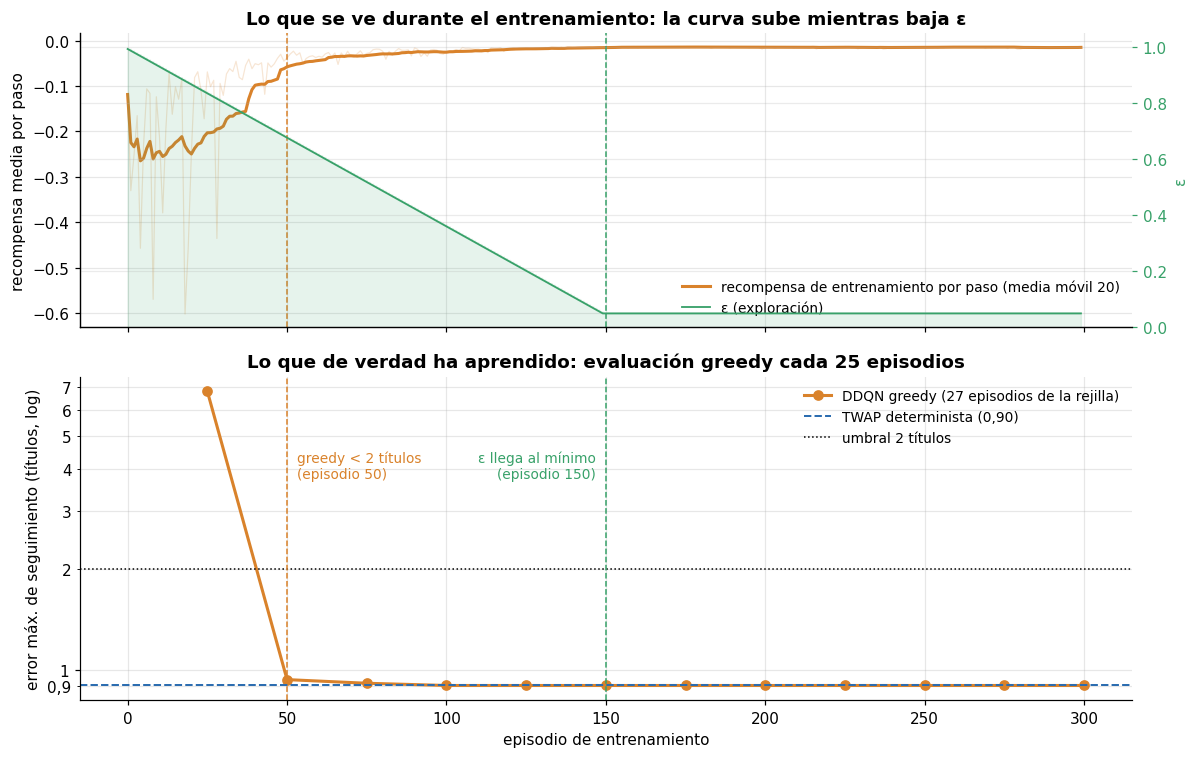

correlación recompensa de entrenamiento (media móvil 20) – ε: -0,85


In [23]:
e3_ep1, e3_ev1 = ej3.load_run("final", "lineal", 0)          # escenario A, ε lineal, semilla 0
e3_epsmin = int(e3_ep1.episode[e3_ep1.epsilon <= 0.05 + 1e-9].min()) + 1
ej3.plot_train_vs_greedy(e3_ep1, e3_ev1, e3_twap, e3_epsmin, save_as=None); plt.show()
e3_rps = (e3_ep1.reward / e3_ep1.steps).rolling(20, min_periods=1).mean()
print(f"correlación recompensa de entrenamiento (media móvil 20) – ε: {np.corrcoef(e3_rps, e3_ep1.epsilon)[0, 1]:.2f}".replace(".", ","))

## 3.2 ¿Cómo trasladamos esa mejora a ε?

> 🔧 **Bloque modificado · Ej. 3** — en lugar de `epsilon = max(epsilon - epsilon_decay, min_epsilon)` en cada episodio, ε solo cambia tras cada evaluación, según el progreso medido.

Progreso en escala log entre E0 = 49,89 y E* = 0,90: $p = \mathrm{clip}\big(\tfrac{\ln E_0 - \ln E}{\ln E_0 - \ln E^*}, 0, 1\big)$; luego
$\varepsilon = 1 - 0{,}95\,p_{ref}$, con $p_{ref}$ el **mejor** progreso. Si p cae más de 0,1 bajo $p_{ref}$ en 2 evaluaciones
seguidas, $p_{ref}$ ← p y ε sube hasta lo que corresponde (no a 1). D-3.2 y D-3.3.

In [24]:
codigo(ex.ImprovementEpsilon, desde="def progress")

**`ImprovementEpsilon`** · `notebooks/common/exploration.py`

```python
def progress(self, error):
    f = np.log if self.log_scale else (lambda x: x)
    span = f(self.base_error) - f(self.target_error)
    if span <= 0:
        return 1.0
    return float(np.clip((f(self.base_error) - f(max(error, 1e-12))) / span, 0.0, 1.0))

def on_eval(self, agent, metric):
    if self.base_error is None:
        self.base_error = max(metric, self.target_error)
    p = self.progress(metric)
    if p >= self.best_progress:
        self.best_progress, self._worse = p, 0
    elif p < self.best_progress - self.margin:
        self._worse += 1
        if self._worse >= self.patience:
            self.best_progress, self._worse = p, 0
    else:
        self._worse = 0  # dentro del margen: la racha de empeoramientos se corta
    agent.epsilon = self.eps_max - (self.eps_max - self.eps_min) * self.best_progress
    self.history.append({"metric": metric, "progress": p, "ref": self.best_progress, "epsilon": agent.epsilon})
```

Una ejecución del escenario inestable (B, semilla 0): ε baja a saltos cuando E baja y vuelve a subir cuando el agente empeora
de forma sostenida. El ε lineal, en gris, baja igual pase lo que pase.

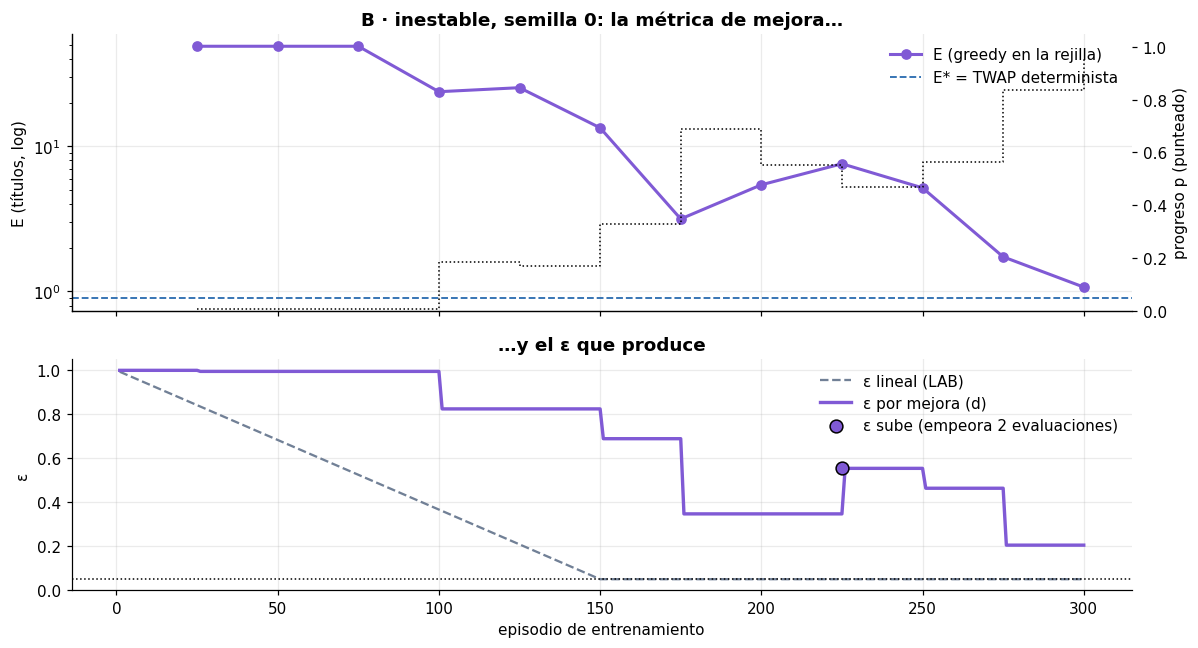

In [25]:
e3_g = lambda df, sc, s, sd: df[(df.config == sc) & (df.schedule == s) & (df.seed == sd)].sort_values("episode")
e3_evd, e3_trd, e3_trl = e3_g(e3_ev, "inestable", "mejora_d", 0), e3_g(e3_tr, "inestable", "mejora_d", 0), e3_g(e3_tr, "inestable", "lineal", 0)
e3_p = np.clip(np.log(e3_e0 / e3_evd.max_err) / np.log(e3_e0 / e3_twap), 0, 1)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
a1.plot(e3_evd.episode, e3_evd.max_err, "o-", color=ej3.SCHED5["mejora_d"][1], lw=2, label="E (greedy en la rejilla)")
a1.axhline(e3_twap, color=lab.MKT, ls="--", lw=1.2, label="E* = TWAP determinista")
a1.set_yscale("log"); a1.set_ylabel("E (títulos, log)"); a1.legend(loc="upper right")
b1 = a1.twinx(); b1.step(e3_evd.episode, e3_p, where="post", color="k", lw=1, ls=":"); b1.set_ylim(0, 1.05)
b1.set_ylabel("progreso p (punteado)"); b1.grid(False)
a1.set_title("B · inestable, semilla 0: la métrica de mejora…")
a2.plot(e3_trl.episode + 1, e3_trl.epsilon, color=lab.GREY, lw=1.5, ls="--", label="ε lineal (LAB)")
a2.plot(e3_trd.episode + 1, e3_trd.epsilon, color=ej3.SCHED5["mejora_d"][1], lw=2.2, label="ε por mejora (d)")
e3_up = e3_evd.epsilon.diff().values > 1e-12
a2.scatter(e3_evd.episode[e3_up], e3_evd.epsilon[e3_up], color=ej3.SCHED5["mejora_d"][1], edgecolor="k", s=70, zorder=4, label="ε sube (empeora 2 evaluaciones)")
a2.axhline(0.05, color="k", ls=":", lw=1); a2.set_ylim(0, 1.05)
a2.set_ylabel("ε"); a2.set_xlabel("episodio de entrenamiento"); a2.legend(loc="upper right")
a2.set_title("…y el ε que produce"); fig.tight_layout(); plt.show()

## 3.3 ¿Funciona? ε lineal frente a ε por mejora

Solo cambia el plan de ε: misma configuración, llenado del buffer, secuencia de episodios, ε inicial = 1, ε_min = 0,05,
300 episodios y evaluación cada 25 también para el lineal (D-3.4). **A** = configuración final del Ej. 2 (estable);
**B** = configuración de partida (`Tracking` c = 5, buffer 50.000), inestable. Línea = media de 3 semillas; banda = mín.-máx.

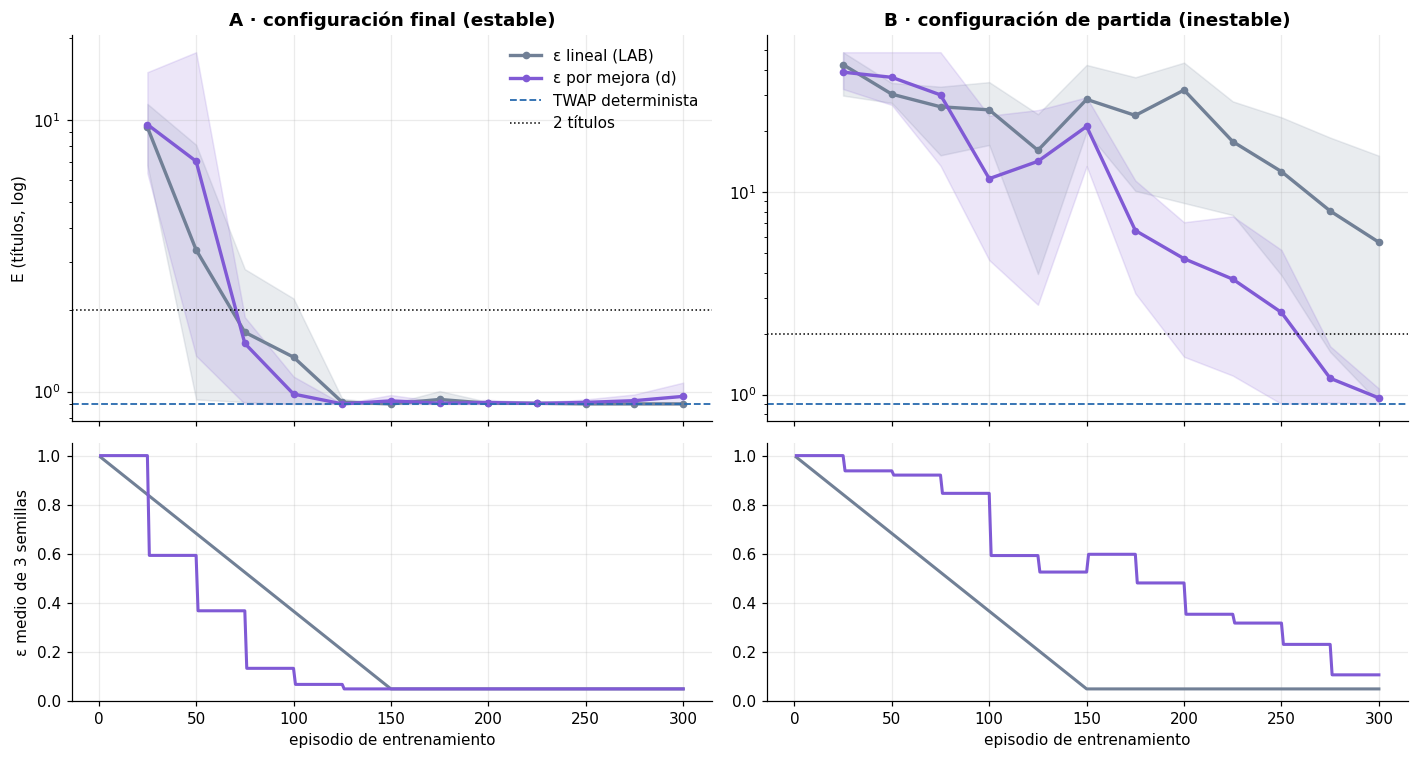

In [26]:
e3_titles = {"final": "A · configuración final (estable)", "inestable": "B · configuración de partida (inestable)"}
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
for j, sc in enumerate(e3_titles):
    for s in ("lineal", "mejora_d"):
        lab_s, col = ("ε lineal (LAB)", lab.GREY) if s == "lineal" else ("ε por mejora (d)", ej3.SCHED5[s][1])
        m = e3_ev[(e3_ev.config == sc) & (e3_ev.schedule == s)].groupby("episode").max_err
        axes[0, j].fill_between(m.mean().index, m.min(), m.max(), color=col, alpha=0.15)
        axes[0, j].plot(m.mean().index, m.mean(), "o-", color=col, lw=2.2, ms=4, label=lab_s)
        t = e3_tr[(e3_tr.config == sc) & (e3_tr.schedule == s)].groupby("episode").epsilon.mean()
        axes[1, j].plot(t.index + 1, t.values, color=col, lw=2, label=lab_s)
    axes[0, j].axhline(e3_twap, color=lab.MKT, ls="--", lw=1.2, label="TWAP determinista")
    axes[0, j].axhline(2, color="k", ls=":", lw=1, label="2 títulos")
    axes[0, j].set_yscale("log"); axes[0, j].set_title(e3_titles[sc])
    axes[1, j].set_ylim(0, 1.05); axes[1, j].set_xlabel("episodio de entrenamiento")
axes[0, 0].set_ylabel("E (títulos, log)"); axes[1, 0].set_ylabel("ε medio de 3 semillas")
axes[0, 0].legend(loc="upper right"); fig.tight_layout(); plt.show()

Tres variantes por mejora y el lineal: **a** E0 = primera evaluación del agente, **c** E0 fijo con escala lineal, **d** E0 fijo con escala log
(media ± desviación de 3 semillas; área = altura media de la curva de E;
1.er ep. E ≤ 2 = media de las semillas que llegan).

In [27]:
e3_rows = []
for (sc, s, sd), g in e3_ev.groupby(["config", "schedule", "seed"]):
    m = ej3.run_metrics(e3_g(e3_tr, sc, s, sd), g.sort_values("episode"))
    e3_rows.append({"escenario": sc, "plan": s, **m, "bajo 2 al final": m["E final"] <= 2})
e3_m = pd.DataFrame(e3_rows)
e3_pm = lambda x: f"{x.mean():.2f} ± {x.std():.2f}".replace(".", ",")
e3_tab = e3_m.groupby(["escenario", "plan"]).agg(**{
    "E final": ("E final", e3_pm), "área E": ("área E (media)", e3_pm),
    "1.er ep. E ≤ 2": ("1.er ep. E ≤ 2", lambda x: f"{x.mean():.0f}"),
    "semillas ≤ 2 al final": ("bajo 2 al final", lambda x: f"{x.sum()}/{len(x)}"),
    "subidas de ε": ("subidas de ε", "sum")})
e3_tab = e3_tab.rename(index={"final": "A", "inestable": "B", "lineal": "ε lineal", "mejora": "a) E0 = 1.ª eval.",
                              "mejora_c": "c) E0 fijo, lineal", "mejora_d": "d) E0 fijo, log"})
display(e3_tab)

E final        área E 1.er ep. E ≤ 2  \
escenario plan                                                           
A         ε lineal            0,90 ± 0,00   1,62 ± 0,63             75   
          a) E0 = 1.ª eval.   0,96 ± 0,09   3,44 ± 2,00             92   
          c) E0 fijo, lineal  0,92 ± 0,02   2,05 ± 1,37             83   
          d) E0 fijo, log     0,96 ± 0,10   1,93 ± 1,10             67   
B         ε lineal            5,65 ± 8,18  22,26 ± 5,74            288   
          a) E0 = 1.ª eval.   1,07 ± 0,28  13,07 ± 7,23            225   
          c) E0 fijo, lineal  1,40 ± 0,59  19,33 ± 3,56            275   
          d) E0 fijo, log     0,96 ± 0,09  13,85 ± 4,50            242   

                             semillas ≤ 2 al final  subidas de ε  
escenario plan                                                    
A         ε lineal                             3/3             0  
          a) E0 = 1.ª eval.                    3/3             0  
          c) E0 fijo, lineal                   3/3             0  
          d) E0 fijo, log                      3/3             0  
B         ε lineal                             2/3             0  
          a) E0 = 1.ª eval.                    3/3             1  
          c) E0 fijo, lineal                   2/3             5  
          d) E0 fijo, log                      3/3             3

## 3.4 Resultado: ayuda cuando el entrenamiento es inestable

En B el ε por mejora vuelve a explorar justo cuando el agente se tuerce. En A el lineal ya llega al TWAP; **d** es la primera en bajar
de 2 títulos (episodio 67 frente a 75), pero acumula algo más de error (área 1,93 frente a 1,62) por los saltos de ε al principio.
**d** es la única variante entre las dos mejores en área E en ambos escenarios.

In [28]:
e3_f = lambda sc, s, col: e3_m[(e3_m.escenario == sc) & (e3_m.plan == s)][col].mean()
e3_n = lambda x, d=2: f"{x:.{d}f}".replace(".", ",")
kpis([("B · E final", f"{e3_n(e3_f('inestable', 'mejora_d', 'E final'))} vs {e3_n(e3_f('inestable', 'lineal', 'E final'))}", "por mejora (d) vs lineal"),
      ("B · área E", f"{e3_n(e3_f('inestable', 'mejora_d', 'área E (media)'))} vs {e3_n(e3_f('inestable', 'lineal', 'área E (media)'))}",
       f"{1 - e3_f('inestable', 'mejora_d', 'área E (media)') / e3_f('inestable', 'lineal', 'área E (media)'):.0%} menos de error acumulado"),
      ("A · E final", f"{e3_n(e3_f('final', 'mejora_d', 'E final'))} vs {e3_n(e3_f('final', 'lineal', 'E final'))}", "sin ganancia: ya era estable"),
      ("A · área E", f"{e3_n(e3_f('final', 'mejora_d', 'área E (media)'))} vs {e3_n(e3_f('final', 'lineal', 'área E (media)'))}", "el lineal sigue por delante")],
     title="ε por mejora (d) frente a ε lineal · media de 3 semillas")

**Conclusión.** Medir la mejora con una evaluación greedy fija y bajar ε con el mejor progreso hacia el TWAP hace que la
exploración no dependa del número de episodios y estabiliza el entrenamiento inestable (0,96 frente a 5,65 títulos), aunque
no mejora al ε lineal cuando el aprendizaje ya era estable.

# Ejercicio 4 · Mejoras del entorno y del entrenamiento

Las tres ideas del enunciado y dos extras, entrenados con `common/scripts/ej4_*.py`; aquí solo se leen `results/`. Orden B → C → A: C entrena el agente de B y A parte de la recompensa de B. Detalle en [ej4_extras.ipynb](ej4_extras.ipynb) y en las decisiones D-4.1 a D-4.5 de [DECISIONES.md](../docs/DECISIONES.md).

| Idea | Qué hacemos | Resultado |
|---|---|---|
| **B** · acabar al 90 % | Plan que termina al 90 % del tiempo + castigo final por títulos pendientes | Compra todo y acaba al **89 %** del tiempo |
| **C** · parar y reanudar | Examen cada 25 episodios, reglas de parada, checkpoints completos | Para en **100-150** episodios en vez de 300 |
| **A** · mirar el mercado | Estado con 4 datos del libro y tendencia + castigo por el spread pagado | **+0,15 pb** por orden frente al TWAP al 90 % |
| Extras · pasillo y robustez | Pasillo 80-95 %; órdenes fuera de rango y empezar con retraso | **100 %** de órdenes completas en las pruebas nuevas |

## 4.1 Idea B · Acabar hacia el 90 % sin dejar volumen pendiente

> 🔧 **Bloque modificado · Ej. 4** — la recompensa sigue un plan que acaba en 0,9·N (no en N) y añade −k·pendiente/n al cierre.

De clase y del enunciado tomamos la banda aceptada (**80-95 %** del tiempo, todo comprado) y la necesidad de calibrar.
Recompensa del ej. 2 (seguir el plan) con un plan que termina al 90 % y, al final, **−k · pendiente / n**. Calibración
con políticas fijas: dejar el último 5 % cuesta 6,2 por separarse del plan y solo 0,04 por el castigo final (k = 1).
Probamos k = 0, 1, 10, 50 y γ = 0,995 (D-4.1).

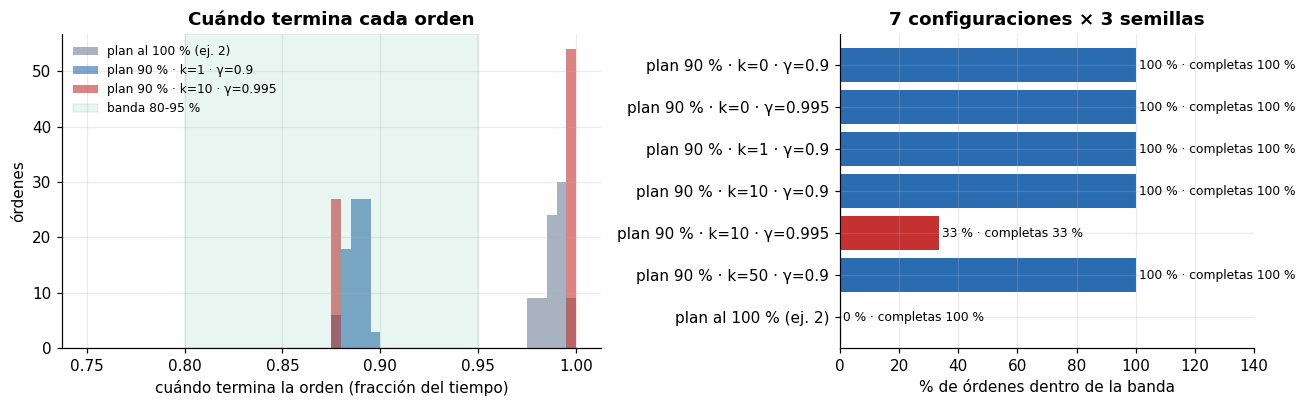

In [29]:
e4_B, e4_B5, e4_BT = pr.load_df("ej4_ideaB"), pr.load_df("ej4_ideaB_5semillas"), pr.load_df("ej4_ideaB_test")
e4_B["config"] = ["plan al 100 % (ej. 2)" if h == 1 else f"plan 90 % · k={k:g} · γ={g:g}"
                  for h, k, g in zip(e4_B.horizon, e4_B.k, e4_B.gamma)]
e4_dd = e4_BT[e4_BT.policy == "DDQN"]
e4_pct = lambda x, d=1: f"{100 * x:.{d}f} %".replace(".", ",")
kpis([("Acaba en (5 semillas, train)", e4_pct(e4_B5.t_fin.mean()), "objetivo ≈ 90 %, banda 80-95 %"),
      ("Órdenes completas · test", e4_pct(e4_dd.completed.mean(), 0), f"3 semillas, acaba en {e4_pct(e4_dd.t_fin.mean())}"),
      ("Dentro de la banda · test", e4_pct(e4_dd.in_band.mean(), 0), "test mirado una sola vez"),
      ("Error frente al plan", f"{e4_B5.max_err_h.mean():.2f}".replace(".", ","), "títulos, igual que el TWAP al 90 %")],
     title="Configuración elegida: plan al 90 %, k = 1, γ = 0,9")

e4_g = e4_B.groupby("config")
e4_tab = pd.DataFrame({"completas %": e4_g.completed.mean() * 100, "en banda %": e4_g.in_band.mean() * 100,
                       "acaba en %": e4_g.t_fin.mean() * 100, "error": e4_g.max_err_h.mean()})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
e4_bins = np.linspace(0.75, 1.0, 51)
for cfg, col in [("plan al 100 % (ej. 2)", lab.GREY), ("plan 90 % · k=1 · γ=0.9", lab.MKT),
                 ("plan 90 % · k=10 · γ=0.995", lab.KO)]:
    ax1.hist(e4_B[e4_B.config == cfg].t_fin, bins=e4_bins, alpha=0.6, color=col, label=cfg)
ax1.axvspan(0.8, 0.95, color=lab.OK, alpha=0.1, label="banda 80-95 %")
ax1.set(xlabel="cuándo termina la orden (fracción del tiempo)", ylabel="órdenes", title="Cuándo termina cada orden")
ax1.legend(fontsize=8)
e4_c = [lab.GREY if "100" in c else (lab.KO if t < 100 else lab.MKT) for c, t in zip(e4_tab.index, e4_tab["en banda %"])]
ax2.barh(e4_tab.index, e4_tab["en banda %"], color=e4_c)
for y, (b, c) in enumerate(zip(e4_tab["en banda %"], e4_tab["completas %"])):
    ax2.text(b + 1, y, f"{b:.0f} % · completas {c:.0f} %", va="center", fontsize=8)
ax2.set(xlim=(0, 140), xlabel="% de órdenes dentro de la banda", title="7 configuraciones × 3 semillas")
ax2.invert_yaxis(); plt.tight_layout(); plt.show()

**Lectura.** Con γ = 0,9 el valor de k no cambia nada: lo que lleva a la banda es el plan al 90 %, y el cierre heredado del Ej. 2
ya cobra lo pendiente. Dejamos k = 1 como red barata. Con γ = 0,995, un castigo grande (k = 10) desestabiliza y deja órdenes
a medias (33 % completas): calibrar k importa, y demasiado es peor que nada.

## 4.2 Idea C · Parar según el aprendizaje, guardar y recuperar

> 🔧 **Bloque modificado · Ej. 4** — el bucle de entrenamiento del LAB pasa a `ej4.Trainer`: reglas de parada y checkpoints reanudables.

Del enunciado tomamos las tres piezas: parar según el aprendizaje, guardar pesos periódicamente y poder reanudar.
`ej4.Trainer` examina al agente cada 25 episodios sobre las 27 órdenes fijas y para por objetivo (error ≤ 1,5 dos
veces seguidas), estancamiento (6 exámenes sin mejorar) o tope (600). Guarda «último» y «mejor» con **todo** el
estado: red, optimizador, memoria, azar y contadores (D-4.2).

In [30]:
codigo(ej4.Trainer._evaluate, desde="if self.target is not None and self.hits >=")
codigo(ej4.Trainer.save, ej4.Trainer.load)

**`Trainer._evaluate`** · `notebooks/common/ej4.py`

```python
if self.target is not None and self.hits >= self.target_hits:
    self.stop_reason = f"objetivo: {self.target_hits} evaluaciones seguidas con error ≤ {self.target}"
elif self.patience and self.since_best >= self.patience:
    self.stop_reason = f"estancamiento: {self.patience} evaluaciones sin mejorar {self.min_delta}"
elif self.episode >= self.max_episodes:
    self.stop_reason = f"tope de {self.max_episodes} episodios"
if self.checkpoint:
    if improved:
        self.save(f"{self.checkpoint}_best.pt", episode=self.episode, metric=metric)
    self.save(f"{self.checkpoint}_last.pt", episode=self.episode, metric=metric)
```

**`Trainer.save`** · `notebooks/common/ej4.py`

```python
def save(self, path, **extra):
    import copy
    import torch
    a = self.agent
    state = {k: copy.deepcopy(getattr(self, k)) for k in self._STATE}
    state.update(buffer=list(a.buffer), agent_rng=a.rng.bit_generator.state,
                 env_rng=self.env.rng.bit_generator.state, torch_rng=torch.get_rng_state())
    a.save(path, trainer=state, **extra)
```

**`Trainer.load`** · `notebooks/common/ej4.py`

```python
def load(self, path):
    import torch
    ckpt = self.agent.load(path)
    st = ckpt["trainer"]
    for k in self._STATE:
        setattr(self, k, st[k])
    self.agent.buffer.clear()
    self.agent.buffer.extend(st["buffer"])
    self.agent.rng.bit_generator.state = st["agent_rng"]
    self.env.rng.bit_generator.state = st["env_rng"]
    torch.set_rng_state(st["torch_rng"])
    return ckpt
```

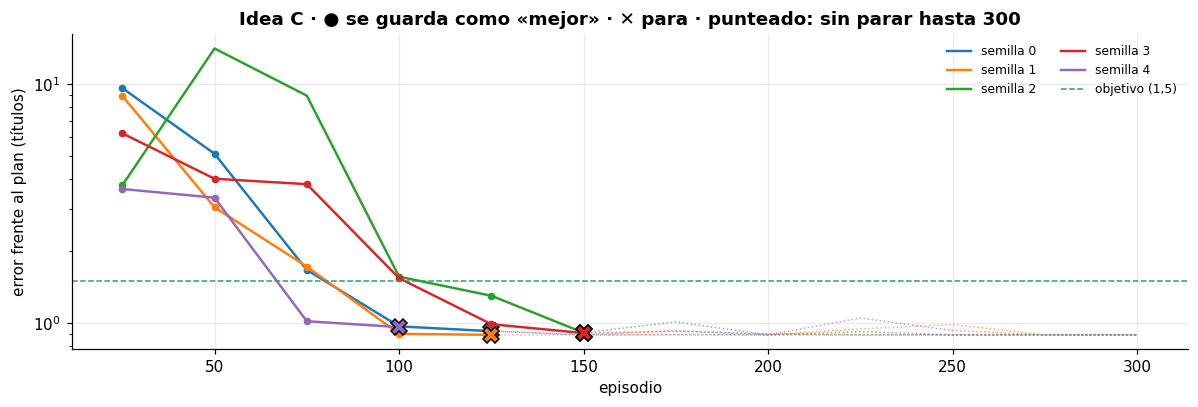

In [31]:
import json
e4_CS = json.loads((pr.RESULTS / "ej4_ideaC.json").read_text(encoding="utf-8"))
e4_CE, e4_CF, e4_CFIN = pr.load_df("ej4_ideaC_evals"), pr.load_df("ej4_ideaC_evals_fijo"), pr.load_df("ej4_ideaC_final")
e4_ep = pd.DataFrame(e4_CS["runs"]).set_index("seed").episodes
e4_err = e4_CFIN.groupby("checkpoint").max_err_h.mean()
e4_demo = e4_CS["demo"]
kpis([("Episodios hasta parar", f"{e4_ep.min()}-{e4_ep.max()}", f"media {e4_ep.mean():.0f}, frente a {e4_CS['fixed_episodes']} fijos"),
      ("Error con parada (mejor)", f"{e4_err['best']:.2f}".replace(".", ","), f"sin parada: {e4_err['sin parada · best']:.2f}".replace(".", ",")),
      ("Reanudación", "idéntica" if e4_demo["curves_equal"] and e4_demo["weights_equal"] else "distinta",
       f"corte en ep. {e4_demo['cut_episode']}, carga del ep. {e4_demo['checkpoint_episode']}: curvas y pesos iguales")])

fig, ax = plt.subplots(figsize=(11, 3.8))
e4_cols = plt.cm.tab10.colors
for s, g in e4_CF.groupby("seed"):
    ax.plot(g.episode, g.max_err_h, ":", color=e4_cols[s], lw=1, alpha=0.6)
for s, g in e4_CE.groupby("seed"):
    ax.plot(g.episode, g.max_err_h, "-", color=e4_cols[s], lw=1.6, label=f"semilla {s}")
    ax.plot(g[g.saved_best].episode, g[g.saved_best].max_err_h, "o", color=e4_cols[s], ms=4)
    ax.plot(g.episode.iloc[-1], g.max_err_h.iloc[-1], "X", color=e4_cols[s], ms=11, mec="k")
ax.axhline(e4_CS["target"], color=lab.OK, ls="--", lw=1, label="objetivo (1,5)")
ax.set(yscale="log", xlabel="episodio", ylabel="error frente al plan (títulos)",
       title="Idea C · ● se guarda como «mejor» · ✕ para · punteado: sin parar hasta 300")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

**Lectura.** Las 5 semillas paran por objetivo con casi el mismo error que con 300 episodios. Cuando la semilla 2
empeora (episodios 25-75), la copia «mejor» no se sobrescribe; el último checkpoint sí.

## 4.3 Idea A · Mejorar el precio del TWAP mirando el mercado

> 🔧 **Bloque modificado · Ej. 4** — el estado pasa de [T, V] a [T, V, spread, desbalanceo, tendencia, actividad] (`ej4.MarketEnv`).

> 🔧 **Bloque modificado · Ej. 4** — la recompensa de B suma un castigo local por el medio spread pagado (`ej4.TrackingPriceCierre`).

Del enunciado tomamos cambiar recompensa **y** estado, valorando el razonamiento más que la cifra. El agente ve 4 datos calculados solo con el pasado (spread, desbalanceo, tendencia y actividad del último minuto) y la
recompensa de B suma w · (mid − precio pagado) / mid en pb: como se compra al ask, es un castigo proporcional al medio
spread pagado, que empuja a comprar cuando el spread es estrecho. Controles: **placebo** (datos barajados), una **regla
simple** («adelanta una compra si el spread está en el mínimo») y w elegido en validación (0,03, el mayor de la rejilla 0 · 0,01 · 0,03), test mirado una vez (D-4.3).

In [32]:
codigo(ej4.MarketEnv.observation_builder, ej4.TrackingPriceCierre.step)

**`MarketEnv.observation_builder`** · `notebooks/common/ej4.py`

```python
def observation_builder(self):
    i = min(self.state_pos, len(self._feat) - 1)
    return np.concatenate([[self.time_left(), self.vol_left()], self._feat[i]])
```

**`TrackingPriceCierre.step`** · `notebooks/common/ej4.py`

```python
def step(self, env, price, vol):
    r = super().step(env, price, vol)
    if vol > 0:
        mid = env._mid[env.state_pos]
        r += self.price_weight * (mid - price) / mid * 1e4
    return r
```

,completas %,en banda %,ahorro medio (pb),± error media,dispersión (pb),slippage vs VWAP (pb),desv. slippage (pb)
politica,,,,,,,
DDQN mercado,100.0,100.0,0.15,0.01,0.40,-2.19,4.71
DDQN placebo,100.0,100.0,-0.02,0.01,0.34,-2.36,4.76
"TWAP 0,9·N",100.0,100.0,0.00,0.00,0.00,-2.34,4.85
regla spread,100.0,100.0,0.34,0.07,1.11,-2.00,5.41


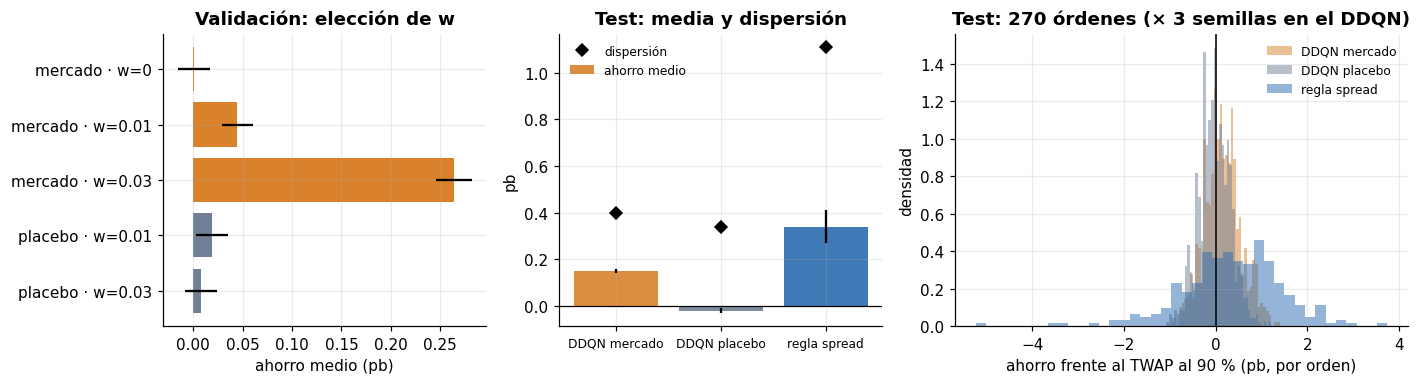

In [33]:
e4_AV, e4_AT = pr.load_df("ej4_ideaA_val"), pr.load_df("ej4_ideaA_test")
e4_AV["agente"] = [f"{'placebo' if p else 'mercado'} · w={w:g}" for w, p in zip(e4_AV.w, e4_AV.placebo)]
e4_gv, e4_gt = e4_AV.groupby("agente").slip_vs_ref_bps, e4_AT.groupby("politica").slip_vs_ref_bps
e4_TA = pd.DataFrame({"completas %": e4_AT.groupby("politica").completed.mean() * 100,
                      "en banda %": e4_AT.groupby("politica").in_band.mean() * 100,
                      "ahorro medio (pb)": e4_gt.mean(), "± error media": e4_gt.std() / np.sqrt(e4_gt.size()),
                      "dispersión (pb)": e4_gt.std(),
                      "slippage vs VWAP (pb)": e4_AT.groupby("politica").slippage_bps.mean(),
                      "desv. slippage (pb)": e4_AT.groupby("politica").slippage_bps.std()}).round(2)
display(e4_TA)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.4]})
e4_v = e4_gv.mean()
ax1.barh(e4_v.index, e4_v.values, xerr=(e4_gv.std() / np.sqrt(e4_gv.size())).values,
         color=[lab.GREY if "placebo" in i else lab.ALGO for i in e4_v.index])
ax1.set(xlabel="ahorro medio (pb)", title="Validación: elección de w"); ax1.invert_yaxis()
e4_pols = ["DDQN mercado", "DDQN placebo", "regla spread"]
e4_pc = [lab.ALGO, lab.GREY, lab.MKT]
ax2.bar(e4_pols, e4_TA.loc[e4_pols, "ahorro medio (pb)"], yerr=e4_TA.loc[e4_pols, "± error media"], color=e4_pc, alpha=0.9,
        label="ahorro medio")
ax2.plot(e4_pols, e4_TA.loc[e4_pols, "dispersión (pb)"], "kD", label="dispersión")
ax2.axhline(0, color="k", lw=0.8); ax2.set(ylabel="pb", title="Test: media y dispersión"); ax2.legend(fontsize=8)
ax2.tick_params(axis="x", labelsize=8)
for p, c in zip(e4_pols, e4_pc):
    ax3.hist(e4_AT[e4_AT.politica == p].slip_vs_ref_bps, bins=40, alpha=0.5, color=c, label=p, density=True)
ax3.axvline(0, color="k", lw=1); ax3.set(xlabel="ahorro frente al TWAP al 90 % (pb, por orden)", ylabel="densidad", title="Test: 270 órdenes (× 3 semillas en el DDQN)")
ax3.legend(fontsize=8); plt.tight_layout(); plt.show()

**Lectura.** En test ahorra +0,15 ± 0,01 pb y el placebo nada (−0,02): la mejora viene de la información. La regla
simple ahorra más (+0,34) pero con casi el triple de dispersión (1,11 frente a 0,40 pb). Frente al VWAP del mercado
(columnas de slippage), el agente también dispersa algo menos que el TWAP y la regla, algo más.

## 4.4 Extras · Pasillo 80-95 % y robustez

> 🔧 **Bloque modificado · Ej. 4** — recompensa de pasillo (`ej4.BandTracking`): 0 dentro del pasillo, castigo por la distancia fuera.

De clase tomamos la banda de finalización y la pregunta de si el agente generaliza. **Pasillo** (D-4.4): sin
castigo entre «acabar al 80 %» y «acabar al 95 %», para que el agente elija. **Robustez** (D-4.5): el agente de B ante
órdenes fuera del rango de entrenamiento (250-800 pasos, 4-20 % del volumen) y sin poder comprar el 20-60 % inicial.

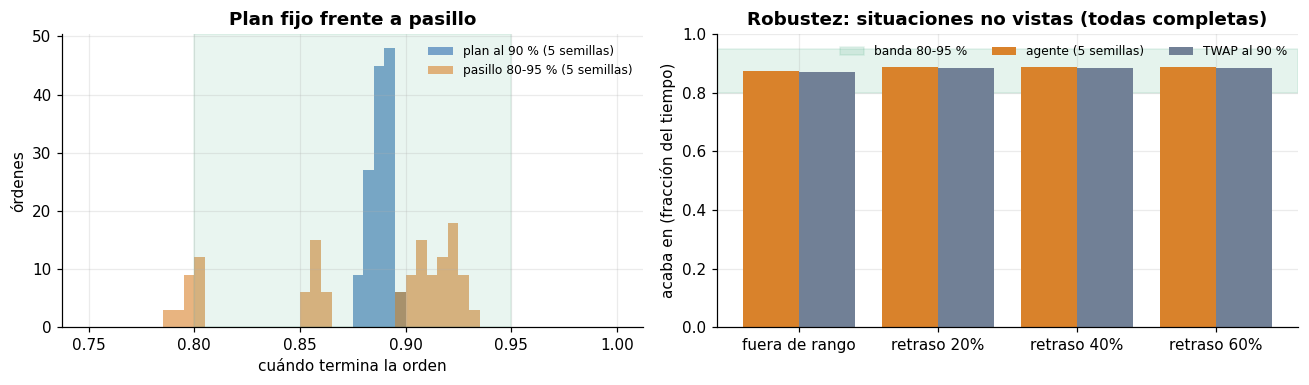

In [34]:
e4_BD, e4_R = pr.load_df("ej4_banda"), pr.load_df("ej4_robustez")
e4_R["quién"] = np.where(e4_R.seed < 0, "TWAP al 90 %", "agente (5 semillas)")
e4_bs = e4_BD.groupby("seed")
kpis([("Pasillo · acaba en (por semilla)", " · ".join(e4_pct(t, 0) for t in e4_bs.t_fin.mean()), "cada semilla elige su punto"),
      ("Pasillo · separación del TWAP al 90 %", f"{e4_bs.max_err_h.mean().min():.1f}-{e4_bs.max_err_h.mean().max():.1f}".replace(".", ","),
       f"plan fijo: {e4_B5.max_err_h.mean():.1f}".replace(".", ",")),
      ("Robustez · órdenes completas", e4_pct(e4_R[e4_R.seed >= 0].completed.mean(), 0), "fuera de rango y con retraso"),
      ("Robustez · dentro de la banda", e4_pct(e4_R[e4_R.seed >= 0].in_band.mean(), 0), "igual que el TWAP al 90 %")])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
ax1.hist(e4_B5.t_fin, bins=e4_bins, alpha=0.6, color=lab.MKT, label="plan al 90 % (5 semillas)")
ax1.hist(e4_BD.t_fin, bins=e4_bins, alpha=0.6, color=lab.ALGO, label="pasillo 80-95 % (5 semillas)")
ax1.axvspan(0.8, 0.95, color=lab.OK, alpha=0.1)
ax1.set(xlabel="cuándo termina la orden", ylabel="órdenes", title="Plan fijo frente a pasillo"); ax1.legend(fontsize=8)
e4_rt = e4_R.groupby(["prueba", "quién"]).t_fin.mean().unstack()
e4_x = np.arange(len(e4_rt))
ax2.bar(e4_x - 0.2, e4_rt["agente (5 semillas)"], 0.4, color=lab.ALGO, zorder=2, label="agente (5 semillas)")
ax2.bar(e4_x + 0.2, e4_rt["TWAP al 90 %"], 0.4, color=lab.GREY, zorder=2, label="TWAP al 90 %")
ax2.axhspan(0.8, 0.95, color=lab.OK, alpha=0.12, zorder=0, label="banda 80-95 %")
ax2.set(xticks=e4_x, xticklabels=e4_rt.index, ylim=(0, 1.0), ylabel="acaba en (fracción del tiempo)",
        title="Robustez: situaciones no vistas (todas completas)"); ax2.legend(fontsize=8, loc="upper right", ncol=3)
plt.tight_layout(); plt.show()

**Lectura.** El pasillo da libertad pero menos estabilidad (una semilla se sale de la banda en más de la mitad de las
órdenes): nos quedamos con el plan fijo. Con órdenes nunca vistas o empezando tarde, compra todo dentro de la banda, como el TWAP.

**Conclusión.** Un plan que acaba al 90 % basta para cumplir la banda de forma estable (B), parar por objetivo ahorra
más de la mitad del entrenamiento sin perder calidad y se reanuda exactamente (C), y mirar el mercado da una mejora
pequeña pero real, confirmada por el placebo, aunque no gana en media a una regla simple (A).